# Analysis of NYC Parks Department Daily Tasks Records

### Filter and Merge Park Task Data and Census Data

Analysis: to determine which Parks properties receive the least (and most) attention for cleaning and maitenance by Parks Department crews.

Goal: to compare neighborhood-level demographic and income data to park cleaning tasks

#### Import Pandas

In [1]:
# !pip install pandas

import pandas as pd

#### Start with 2025 Data

This data set covers the full year (2025) of daily Parks crew tasks. This will establish the baseline, before analyzing 2026, which is incomplete (from January to October, when the data was pulled).

In [2]:
data_25 = pd.read_csv('../data/Daily_Tasks_Park_Cleaning_Records_2025_Jan1-Dec31.csv')

data_25.head(5)

,row_id,gispropnum,omppropid,gisobjid,route_id,off_route,description,district,sector,sector_name,...,nnpw,ncrew,fixed_post,nhours,daily_task_id,daily_task_activity_id,overlap_flag,fiscal_day,fiscal_week,fiscal_qtr
0,1920785,NaN,NaN,NaN,1815.0,NaN,NaN,NaN,M-S4.5,Manhattan Sector 4.5,...,0,2,No,0.50,1920785,7945036,0,184,26,2025Q3
1,1920994,B145,B145,100004507.0,1753.0,No,B145 | Thomas Greene Playground,B-06,B-S6.7,Brooklyn Sector 6.7,...,0,3,No,0.53,1920994,7946300,1,184,26,2025Q3
2,1920751,B098,B098,100004630.0,1755.0,No,B098 | Martin Luther Playground,B-07,B-S6.7,Brooklyn Sector 6.7,...,0,3,No,0.58,1920751,7945055,0,184,26,2025Q3
3,1920955,Q099,Q099-ZN19,100000576.0,1965.0,No,Q099-ZN19 | Flushing Meadows Park-Ballfields,Q-15,Q-S15,Queens Sector 15,...,0,4,No,0.50,1920955,7945923,0,184,26,2025Q3
4,1920640,NaN,NaN,NaN,2589.0,NaN,NaN,NaN,X-S7.8,Bronx Sector 7.8,...,0,2,No,1.00,1920640,7945483,0,184,26,2025Q3


#### Column Names and Total Number of Rows

In [3]:
print(
    data_25.columns
)

print(
    len(data_25)
)

Index(['row_id', 'gispropnum', 'omppropid', 'gisobjid', 'route_id',
       'off_route', 'description', 'district', 'sector', 'sector_name',
       'sector_desc', 'vehicle_number', 'date_worked', 'start_time',
       'end_time', 'activity', 'animal_waste', 'broken_glass', 'dumping',
       'graffiti', 'medical_waste', 'napsw', 'ncpw', 'ncsa', 'npop', 'nnpw',
       'ncrew', 'fixed_post', 'nhours', 'daily_task_id',
       'daily_task_activity_id', 'overlap_flag', 'fiscal_day', 'fiscal_week',
       'fiscal_qtr'],
      dtype='str')
1510365


#### Drop Columns Not Needed For Analysis

In [4]:
data_25 = data_25.drop(columns=['omppropid', 'gisobjid', 'vehicle_number', 'napsw', 'ncpw', 'ncsa', 'npop', 'nnpw', 'overlap_flag', 'fiscal_day', 'fiscal_week', 'fiscal_qtr'])

print(data_25.columns)

Index(['row_id', 'gispropnum', 'route_id', 'off_route', 'description',
       'district', 'sector', 'sector_name', 'sector_desc', 'date_worked',
       'start_time', 'end_time', 'activity', 'animal_waste', 'broken_glass',
       'dumping', 'graffiti', 'medical_waste', 'ncrew', 'fixed_post', 'nhours',
       'daily_task_id', 'daily_task_activity_id'],
      dtype='str')


#### Data types

In [5]:
data_25.dtypes

row_id                      int64
gispropnum                    str
route_id                  float64
off_route                     str
description                   str
district                      str
sector                        str
sector_name                   str
sector_desc                   str
date_worked                   str
start_time                    str
end_time                      str
activity                      str
animal_waste                  str
broken_glass                  str
dumping                       str
graffiti                      str
medical_waste                 str
ncrew                       int64
fixed_post                    str
nhours                    float64
daily_task_id               int64
daily_task_activity_id      int64
dtype: object

#### Create a datetime column

To stay organized, I'm going to index the spreadsheet in chronological order. To do that, I make a new "converted_date" column in the correct datetime format.

In [6]:
data_25['date_worked']

0          01/01/2025
1          01/01/2025
2          01/01/2025
3          01/01/2025
4          01/01/2025
              ...    
1510360    12/31/2025
1510361    12/31/2025
1510362    12/31/2025
1510363    12/31/2025
1510364    12/31/2025
Name: date_worked, Length: 1510365, dtype: str

In [7]:
data_25['converted_date_worked'] = data_25['date_worked'].astype('datetime64[ns]')

# make sure the column was made, and in the correct dtype
data_25.dtypes

row_id                             int64
gispropnum                           str
route_id                         float64
off_route                            str
description                          str
district                             str
sector                               str
sector_name                          str
sector_desc                          str
date_worked                          str
start_time                           str
end_time                             str
activity                             str
animal_waste                         str
broken_glass                         str
dumping                              str
graffiti                             str
medical_waste                        str
ncrew                              int64
fixed_post                           str
nhours                           float64
daily_task_id                      int64
daily_task_activity_id             int64
converted_date_worked     datetime64[ns]
dtype: object

In [8]:
data_25.head(5)

,row_id,gispropnum,route_id,off_route,description,district,sector,sector_name,sector_desc,date_worked,...,broken_glass,dumping,graffiti,medical_waste,ncrew,fixed_post,nhours,daily_task_id,daily_task_activity_id,converted_date_worked
0,1920785,NaN,1815.0,NaN,NaN,NaN,M-S4.5,Manhattan Sector 4.5,"Districts 4, 5",01/01/2025,...,No,No,No,No,2,No,0.50,1920785,7945036,2025-01-01
1,1920994,B145,1753.0,No,B145 | Thomas Greene Playground,B-06,B-S6.7,Brooklyn Sector 6.7,"Districts 6, 7",01/01/2025,...,Yes,No,Yes,No,3,No,0.53,1920994,7946300,2025-01-01
2,1920751,B098,1755.0,No,B098 | Martin Luther Playground,B-07,B-S6.7,Brooklyn Sector 6.7,"Districts 6, 7",01/01/2025,...,Yes,No,No,No,3,No,0.58,1920751,7945055,2025-01-01
3,1920955,Q099,1965.0,No,Q099-ZN19 | Flushing Meadows Park-Ballfields,Q-15,Q-S15,Queens Sector 15,District 15,01/01/2025,...,No,No,No,No,4,No,0.50,1920955,7945923,2025-01-01
4,1920640,NaN,2589.0,NaN,NaN,NaN,X-S7.8,Bronx Sector 7.8,"Districts 7, 8",01/01/2025,...,No,No,No,No,2,No,1.00,1920640,7945483,2025-01-01


#### Determine Duplicates

I don't want to count duplicate records

In [9]:
# number of duplicate rows in dataset

data_25.duplicated().sum()

np.int64(206401)

In [10]:
data_25[data_25.duplicated()].head() # view the first 5 duplicates

,row_id,gispropnum,route_id,off_route,description,district,sector,sector_name,sector_desc,date_worked,...,broken_glass,dumping,graffiti,medical_waste,ncrew,fixed_post,nhours,daily_task_id,daily_task_activity_id,converted_date_worked
7,1920864,XZ307,2721.0,Yes,XZ307 | Washington Ave. And East 159th St.,X-03,X-S3.6,Bronx Sector 3.6,"Districts 3, 6",01/01/2025,...,Yes,No,No,No,2,No,0.33,1920864,7945400,2025-01-01
8,1920864,XZ307,2721.0,Yes,XZ307 | Washington Ave. And East 159th St.,X-03,X-S3.6,Bronx Sector 3.6,"Districts 3, 6",01/01/2025,...,Yes,No,No,No,2,No,0.33,1920864,7945400,2025-01-01
25,1921606,X010,NaN,No,X010-ZN09 | Crotona Park-Crotona Zone 9,X-03,X-S3.6,Bronx Sector 3.6,"Districts 3, 6",01/01/2025,...,No,No,No,No,2,Yes,8.50,1921606,7949584,2025-01-01
26,1921606,X010,NaN,No,X010-ZN09 | Crotona Park-Crotona Zone 9,X-03,X-S3.6,Bronx Sector 3.6,"Districts 3, 6",01/01/2025,...,No,No,No,No,2,Yes,8.50,1921606,7949584,2025-01-01
31,1920665,X146,2709.0,Yes,X146 | Flynn Playground,X-01,X-S1.2,Bronx Sector 1.2,"Districts 1, 2",01/01/2025,...,No,No,No,No,1,No,0.23,1920665,7946513,2025-01-01


In [11]:
deduped_25 = data_25.drop_duplicates(keep='first')

In [12]:
# check to make sure duplicate rows were dropped

deduped_25.shape

(1303964, 24)

#### Drop NaN values

Since our analysis relies on data from the gispropnum column, rows with empty values in this column are unhelpful for analysis

In [13]:
deduped_25.isnull().sum() # provides the numnber of missing values in each column

row_id                         0
gispropnum                260976
route_id                  294355
off_route                 247731
description               260976
district                  260976
sector                      5184
sector_name                68107
sector_desc                68107
date_worked                    0
start_time                     0
end_time                       0
activity                       0
animal_waste                   0
broken_glass                   0
dumping                        0
graffiti                       0
medical_waste                  0
ncrew                          0
fixed_post                     0
nhours                         0
daily_task_id                  0
daily_task_activity_id         0
converted_date_worked          0
dtype: int64

In [14]:
# Because we need to merge this dataset with the Parks Properties list, we will drop any rows that do not identify the specific park property

cleaned_25 = deduped_25.dropna(subset=['gispropnum'])

cleaned_25.shape

(1042988, 24)

In [15]:
cleaned_25.sample(5)

,row_id,gispropnum,route_id,off_route,description,district,sector,sector_name,sector_desc,date_worked,...,broken_glass,dumping,graffiti,medical_waste,ncrew,fixed_post,nhours,daily_task_id,daily_task_activity_id,converted_date_worked
870312,2031803,Q098,1906.0,Yes,Q098-01 | O'Connors Tail-O'Connor's Tail,Q-04,Q-S3.4,Queens Sector 3.4,"Districts 3, 4",07/30/2025,...,No,No,No,No,3,No,0.25,2031803,8497720,2025-07-30
187850,1947187,X179,NaN,No,X179 | Al Quiñones Playground,X-02,X-S1.2,Bronx Sector 1.2,"Districts 1, 2",02/17/2025,...,No,No,No,No,2,Yes,3.13,1947187,8084291,2025-02-17
973444,2045590,X148E,2746.0,No,X148E | Peace Park,X-05,X-S4.5,Bronx Sector 4.5,"Districts 4, 5",08/23/2025,...,No,No,No,No,4,No,0.34,2045590,8561308,2025-08-23
1288835,2086761,M180,2248.0,No,M180 | Lt. Wm. Tighe Triangle,M-12,M-S12.12A,Manhattan Sector 12.12A,"Districts 12, 12A",11/06/2025,...,No,No,No,No,2,No,0.17,2086761,8756432,2025-11-06
585978,1991226,Q465,2830.0,No,Q465 | Socrates Sculpture Park,Q-01,Q-S1.2,Queens Sector 1.2,"Districts 1, 2",05/24/2025,...,No,No,No,No,2,No,0.02,1991226,8320593,2025-05-24


#### Merge Park Properties list data

We want to create a new column in the cleaned_25 data with the park's recognized name

In [16]:
properties = pd.read_csv('../data/Parks_Properties_all.csv')

properties.head()

,ACQUISITIONDATE,ACRES,ADDRESS,BOROUGH,CLASS,COMMUNITYBOARD,COUNCILDISTRICT,DEPARTMENT,GISOBJID,GISPROPNUM,...,PIP_RATABLE,PRECINCT,RETIRED,SIGNNAME,SUBCATEGORY,TYPECATEGORY,US_CONGRESS,WATERFRONT,ZIPCODE,multipolygon
0,1997 Jul 15 12:00:00 AM,0.351,864 REV JAMES POLITE AVENUE,X,PARK,202,17,X-02,"100,005,159",X164A,...,False,41,False,Wishing Well Garden,Greenthumb,Garden,14,False,10459,MULTIPOLYGON (((-73.89843937884129 40.81969804...
1,1979 Jul 17 12:00:00 AM,0.94,724 FOX STREET,X,PARK,202,17,X-02,"100,004,895",X247,...,True,41,False,Fox Park,Neighborhood Plgd,Neighborhood Park,14,False,10455,MULTIPOLYGON (((-73.89783962787203 40.81493886...
2,1934 Jul 08 12:00:00 AM,0.42,320 6 AVENUE,M,PARK,102,2,M-02,"100,004,406",M125C,...,True,6,False,West 4th Street Courts,Neighborhood Plgd,Playground,10,False,10012,MULTIPOLYGON (((-74.00092286126788 40.73090253...
3,1949 Oct 17 12:00:00 AM,1.254,312 WATER STREET,M,PARK,103,1,M-03,"100,004,672",M206,...,True,5,False,Tanahey Playground,Neighborhood Plgd,Neighborhood Park,10,False,10002,MULTIPOLYGON (((-73.99601102624779 40.70986334...
4,1934 Apr 13 12:00:00 AM,7.85,106 CHRYSTIE STREET,M,PARK,103,1,M-03,"100,003,978",M105,...,True,5,False,Sara D. Roosevelt Park,Large Park,Neighborhood Park,10,False,10002,MULTIPOLYGON (((-73.99218978765998 40.71998285...


In [17]:
properties.columns

Index(['ACQUISITIONDATE', 'ACRES', 'ADDRESS', 'BOROUGH', 'CLASS',
       'COMMUNITYBOARD', 'COUNCILDISTRICT', 'DEPARTMENT', 'GISOBJID',
       'GISPROPNUM', 'GlobalID', 'JURISDICTION', 'LOCATION', 'MAPPED',
       'NAME311', 'NYS_ASSEMBLY', 'NYS_SENATE', 'OBJECTID', 'OMPPROPID',
       'PARENTID', 'PERMIT', 'PERMITDISTRICT', 'PERMITPARENT', 'PIP_RATABLE',
       'PRECINCT', 'RETIRED', 'SIGNNAME', 'SUBCATEGORY', 'TYPECATEGORY',
       'US_CONGRESS', 'WATERFRONT', 'ZIPCODE', 'multipolygon'],
      dtype='str')

In [18]:
properties.dtypes

ACQUISITIONDATE       str
ACRES                 str
ADDRESS               str
BOROUGH               str
CLASS                 str
COMMUNITYBOARD        str
COUNCILDISTRICT       str
DEPARTMENT            str
GISOBJID              str
GISPROPNUM            str
GlobalID              str
JURISDICTION          str
LOCATION              str
MAPPED                str
NAME311               str
NYS_ASSEMBLY          str
NYS_SENATE            str
OBJECTID              str
OMPPROPID             str
PARENTID              str
PERMIT             object
PERMITDISTRICT        str
PERMITPARENT          str
PIP_RATABLE        object
PRECINCT            int64
RETIRED              bool
SIGNNAME              str
SUBCATEGORY           str
TYPECATEGORY          str
US_CONGRESS           str
WATERFRONT         object
ZIPCODE               str
multipolygon          str
dtype: object

In [19]:
properties['gispropnum'] = properties['GISPROPNUM']

properties.head(5)

,ACQUISITIONDATE,ACRES,ADDRESS,BOROUGH,CLASS,COMMUNITYBOARD,COUNCILDISTRICT,DEPARTMENT,GISOBJID,GISPROPNUM,...,PRECINCT,RETIRED,SIGNNAME,SUBCATEGORY,TYPECATEGORY,US_CONGRESS,WATERFRONT,ZIPCODE,multipolygon,gispropnum
0,1997 Jul 15 12:00:00 AM,0.351,864 REV JAMES POLITE AVENUE,X,PARK,202,17,X-02,"100,005,159",X164A,...,41,False,Wishing Well Garden,Greenthumb,Garden,14,False,10459,MULTIPOLYGON (((-73.89843937884129 40.81969804...,X164A
1,1979 Jul 17 12:00:00 AM,0.94,724 FOX STREET,X,PARK,202,17,X-02,"100,004,895",X247,...,41,False,Fox Park,Neighborhood Plgd,Neighborhood Park,14,False,10455,MULTIPOLYGON (((-73.89783962787203 40.81493886...,X247
2,1934 Jul 08 12:00:00 AM,0.42,320 6 AVENUE,M,PARK,102,2,M-02,"100,004,406",M125C,...,6,False,West 4th Street Courts,Neighborhood Plgd,Playground,10,False,10012,MULTIPOLYGON (((-74.00092286126788 40.73090253...,M125C
3,1949 Oct 17 12:00:00 AM,1.254,312 WATER STREET,M,PARK,103,1,M-03,"100,004,672",M206,...,5,False,Tanahey Playground,Neighborhood Plgd,Neighborhood Park,10,False,10002,MULTIPOLYGON (((-73.99601102624779 40.70986334...,M206
4,1934 Apr 13 12:00:00 AM,7.85,106 CHRYSTIE STREET,M,PARK,103,1,M-03,"100,003,978",M105,...,5,False,Sara D. Roosevelt Park,Large Park,Neighborhood Park,10,False,10002,MULTIPOLYGON (((-73.99218978765998 40.71998285...,M105


#### Merge Datasets

In [20]:
merged_25 = cleaned_25.merge(
    properties[['gispropnum', 'ADDRESS', 'BOROUGH', 'CLASS', 'NAME311', 'PARENTID', 'PIP_RATABLE', 'SUBCATEGORY', 'TYPECATEGORY', 'ZIPCODE', 'multipolygon']],
    on='gispropnum',
    how='left'
)

merged_25.columns

Index(['row_id', 'gispropnum', 'route_id', 'off_route', 'description',
       'district', 'sector', 'sector_name', 'sector_desc', 'date_worked',
       'start_time', 'end_time', 'activity', 'animal_waste', 'broken_glass',
       'dumping', 'graffiti', 'medical_waste', 'ncrew', 'fixed_post', 'nhours',
       'daily_task_id', 'daily_task_activity_id', 'converted_date_worked',
       'ADDRESS', 'BOROUGH', 'CLASS', 'NAME311', 'PARENTID', 'PIP_RATABLE',
       'SUBCATEGORY', 'TYPECATEGORY', 'ZIPCODE', 'multipolygon'],
      dtype='str')

In [21]:
merged_25[['converted_date_worked', 'gispropnum', 'activity', 'NAME311', 'PARENTID', 'PIP_RATABLE']].sample(5)

,converted_date_worked,gispropnum,activity,NAME311,PARENTID,PIP_RATABLE
195558,2025-03-12,X001B,Work,Barnhill Square,X-07,True
538062,2025-07-09,M107,Work,Wards Island Park,M-11,False
113422,2025-02-11,X147A,Work,Starlight Park,X-14,False
214350,2025-03-19,M110,Work,William McCray Playground,M-10,True
851394,2025-10-23,X118,Work,Soundview Park,X-09,False


#### Find and Fill Missing NAME311 Values From Matching gispropnum

In [22]:
merged_25.isnull().sum() # provides the number of missing values in each column

row_id                         0
gispropnum                     0
route_id                  294237
off_route                      0
description                    0
district                       0
sector                      5066
sector_name                42344
sector_desc                42344
date_worked                    0
start_time                     0
end_time                       0
activity                       0
animal_waste                   0
broken_glass                   0
dumping                        0
graffiti                       0
medical_waste                  0
ncrew                          0
fixed_post                     0
nhours                         0
daily_task_id                  0
daily_task_activity_id         0
converted_date_worked          0
ADDRESS                   467473
BOROUGH                   192506
CLASS                     192506
NAME311                   192506
PARENTID                  192506
PIP_RATABLE               192875
SUBCATEGOR

In [23]:
merged_25['NAME311'].isnull().sum()

np.int64(192506)

So some names are missing, but I'm wondering if those null values still have matching gispropnums. To fill in all possible name values, I'm creating a "name map", which is essentially a list of park names matched to their respective gispropnum code.

In [24]:
name_map = ( 
    merged_25
    .dropna(subset=['NAME311'])
    .drop_duplicates(subset='gispropnum')
    .set_index('gispropnum')['NAME311']
)

name_map.head()

gispropnum
B145        Thomas Greene Playground
B098        Martin Luther Playground
Q099    Flushing Meadows Corona Park
B389                       Umma Park
Q102             Juniper Valley Park
Name: NAME311, dtype: str

And now I am combining the name map to the merged_25 dataset, so that each park with a gispropnum will also have its respective name. This is more of an extra safety step, just to be sure that all parks with a gispropnum also have a name attached.

In [25]:
merged_25['NAME311'] = (
    merged_25['NAME311']
    .combine_first(merged_25['gispropnum'].map(name_map))
)

# check to see if null values have changed
merged_25['NAME311'].isnull().sum()

np.int64(192506)

In [26]:
merged_25[['PARENTID', 'gispropnum', 'NAME311']].sample(10)

,PARENTID,gispropnum,NAME311
746690,NaN,XZ08,NaN
301461,M-12,M099,J. Hood Wright Park
149911,M-08,M045,John Jay Park
942454,Q-08,Q021,Cunningham Park
1033400,M-03,M171,Cherry Clinton Playground
157561,X-06,X042,Rose Hill Park
599929,Q-08,Q021,Cunningham Park
657959,NaN,BT15,NaN
721262,R-03,R133,Arbutus Woods Park
496660,M-03,M144,John V. Lindsay East River Park


#### Drop NaN Values Again

There are 192.5k null rows in the NAME311 column. Since we can't match a name to those gispropnum values, we will drop them, since they are not likely parks, but some other form of Parks Department property. Either way, we can't analyze them.

In [27]:
merged_25.isnull().sum() # provides the number of missing values in each column

row_id                         0
gispropnum                     0
route_id                  294237
off_route                      0
description                    0
district                       0
sector                      5066
sector_name                42344
sector_desc                42344
date_worked                    0
start_time                     0
end_time                       0
activity                       0
animal_waste                   0
broken_glass                   0
dumping                        0
graffiti                       0
medical_waste                  0
ncrew                          0
fixed_post                     0
nhours                         0
daily_task_id                  0
daily_task_activity_id         0
converted_date_worked          0
ADDRESS                   467473
BOROUGH                   192506
CLASS                     192506
NAME311                   192506
PARENTID                  192506
PIP_RATABLE               192875
SUBCATEGOR

In [28]:
new_25 = merged_25.dropna(subset=['NAME311'])

new_25.shape

(850482, 34)

In [29]:
new_25.sample(10)

,row_id,gispropnum,route_id,off_route,description,district,sector,sector_name,sector_desc,date_worked,...,ADDRESS,BOROUGH,CLASS,NAME311,PARENTID,PIP_RATABLE,SUBCATEGORY,TYPECATEGORY,ZIPCODE,multipolygon
182240,1952883,Q127,1953.0,Yes,Q127 | Marconi Park,Q-12,Q-S10.12,Queens Sector 10.12,"Districts 10, 12",03/08/2025,...,155-01 109 AVENUE,Q,PARK,Marconi Park,Q-12,True,Neighborhood Plgd,Neighborhood Park,11433,MULTIPOLYGON (((-73.79593975451517 40.69261278...
383082,1988990,B003,NaN,No,B003 | Bartel-Pritchard Square,B-19,B-S14.19,Brooklyn Sector 14.19,"Districts 14, 19",05/17/2025,...,NaN,B,PARK,Bartel-Pritchard Square,B-19,True,Sitting Area/Triangle/Mall,Triangle/Plaza,11215,MULTIPOLYGON (((-73.97984506009364 40.66142937...
421067,1995187,M077,2818.0,No,M077-ZN01 | St Nicholas Park Zone 01,M-09,M-S7.9,Manhattan Sector 7.9,"Districts 7, 9",05/30/2025,...,48 ST NICHOLAS AVENUE,M,PARK,St. Nicholas Park,M-09,False,Large Park,Neighborhood Park,"10027, 10031",MULTIPOLYGON (((-73.95043743457018 40.81328725...
671584,2045238,B253,2843.0,No,B253 | Albert L. Parham Playground,B-02,B-S2,Brooklyn Sector 2,District 2,08/22/2025,...,255 ADELPHI STREET,B,PARK,Albert L. Parham Playground,B-02,True,JOP,Jointly Operated Playground,11205,MULTIPOLYGON (((-73.97063986586979 40.68998446...
852996,2079727,Q414,1948.0,Yes,Q414 | Rocket Playground,Q-10,Q-S10.12,Queens Sector 10.12,"Districts 10, 12",10/24/2025,...,88-17 NORTH CONDUIT AVENUE,Q,PARK,Rocket Playground,Q-10,True,JOP,Jointly Operated Playground,11417,MULTIPOLYGON (((-73.84626606026997 40.67098522...
160731,1949645,M200A,1835.0,No,M200A | Anibal Aviles Playground,M-07,M-S7.9,Manhattan Sector 7.9,"Districts 7, 9",02/28/2025,...,111 WEST 108 STREET,M,PARK,Anibal Aviles Playground,M-07,True,JOP,Playground,10025,MULTIPOLYGON (((-73.96263452668934 40.80125912...
97474,1938245,R073,2063.0,No,R073 | Naples Playground,R-02,R-S2.2B,Staten Island Sector 2.2B,"Districts 2, 2B",02/05/2025,...,1055 TARGEE STREET,R,PARK,Naples Playground,R-02,True,JOP,Jointly Operated Playground,10304,MULTIPOLYGON (((-74.08933574465203 40.60296867...
484311,2007948,Q005,2897.0,No,Q005-ZN02 | Baisley Pond Park Zone 2,Q-12,Q-S10.12,Queens Sector 10.12,"Districts 10, 12",06/21/2025,...,116-01 116 AVENUE,Q,PARK,Baisley Pond Park,Q-12,False,Large Park,Community Park,11434,MULTIPOLYGON (((-73.78439768325394 40.67917896...
194344,1954569,Q099,2920.0,Yes,Q099-ZN17 | Flushing Meadows Park-College Poin...,Q-15,Q-S15,Queens Sector 15,District 15,03/12/2025,...,PARK DR E AND 136 ST,Q,PARK,Flushing Meadows Corona Park,Q-15,False,Flagship Park,Flagship Park,"11354, 11355, 11367, 11368",MULTIPOLYGON (((-73.84509867168501 40.75388350...
500908,2011406,R065,2890.0,Yes,R065-ZN12 | S.I. Greenbelt-Field of Dreams,R-02,R-S2.2B,Staten Island Sector 2.2B,"Districts 2, 2B",06/26/2025,...,NaN,R,PARK,Richmond Parkway,R-02,False,Large Park,Parkway,"10301, 10304, 10306, 10309, 10312, 10314",MULTIPOLYGON (((-74.11534319138558 40.59955497...


#### Filter Down to Just Parks

Since the Parks Department also takes care of properties like buildings, street plazas, malls, empty lots, etc. we will drop those. We only want to look at green spaces.

First I want to check a couple parks that I've been looking at as part of my reporting: Calvert Vaux Park and Morningside Park. Two very different parks, in two very different neighborhoods, but both with trash problems. 

In [30]:
calvert = new_25[new_25['NAME311'].str.contains('Calvert', case=False, na=False)]

calvert['description'].value_counts()

description
B125-01 | Calvert Vaux Park Playground    309
B125 | Calvert Vaux Park                    6
Name: count, dtype: int64

In [31]:
morningside = new_25[new_25['NAME311'].str.contains('Morningside', case=False, na=False)]

morningside['description'].value_counts()

description
M056-01 | Morningside Park-Playground 123             750
M056-ZN02 | Morningside Park Zone 2                   693
M056-ZN03 | Morningside Park Zone 3                   649
M056-02 | Morningside Park-Morningside Playground     640
M056-ZN05 | Morningside Park Zone 5                   610
M056-ZN01 | Morningside Park Zone 1                   561
M056-ZN04 | Morningside Park Zone 4                   524
M056-03 | Morningside Park-Morningside Park           489
M056-04 | Morningside Park-110th Street Playground    389
M056 | Morningside Park                               223
Name: count, dtype: int64

Considering that these properties are considered 'Recreational Field' or contain playgrounds means the data is not as easy to pin down. I'm going to include 'Recreational Field/Courts' in my TYPECATEGORY selection, and I'm going to remove all Playground visits from the new_25 list, before analyzing further. 

Playgrounds are interesting, because the city has recently put more attention on playgrounds specifically, but not the rest of the parks that contain them.

#### Remove Playground Visits from Dataset

Again, we're considering park green spaces for this analysis, excluding playgrounds.

In [32]:
new_25 = new_25[~new_25['description'].str.contains('playground', case=False, na=False)]

new_25.shape

(519936, 34)

Test to see if it worked...

In [33]:
new_25['description'].sample(10)

199877                      Q116 | One Room Schoolhouse Park
588490     B088-03 | Herbert Von King Park-Herbert Von Ki...
746619                                   M011 | Chelsea Park
566054                      B018-ZN01 | Canarsie Park Zone 1
958483       M071-ZN06 | Riverside Park-Serpentine Promenade
508811                           X152 | Vinmont Veteran Park
166513                       R150 | Graniteville Quarry Park
447133           X008-ZN02 | Claremont Park-Claremont Zone 2
142229           X008-ZN02 | Claremont Park-Claremont Zone 2
1015476           B073-ZN03 | Prospect Park-Litchfield Villa
Name: description, dtype: str

In [34]:
new_25['description'].value_counts()

description
B073-ZN07 | Prospect Park-South West Entrance                            1613
B087 | Sunset Park                                                       1534
B073-ZN08 | Prospect Park-Park Side Ave                                  1341
R172 | Brookfield Park                                                   1329
B113A | Cadman Plaza Park                                                1282
                                                                         ... 
Q099-QZ698 | GCP (Westbound) & Perimeter Rd & Van Wyck Expwy Entrance       1
M393 | Oasis Garden                                                         1
M382 | 110th Street Block Association Garden                                1
B492 | St John Cantius Parish                                               1
B040 | Grand Army Plaza                                                     1
Name: count, Length: 1645, dtype: int64

#### Now Filter Out the Other Property Types

In [35]:
new_25['SUBCATEGORY'].value_counts()

SUBCATEGORY
Large Park                    204969
Sitting Area/Triangle/Mall    117449
Flagship Park                  66000
Neighborhood Plgd              65688
Neighborhood Park              38807
JOP                             8398
Undeveloped                     7968
Type 1                          1836
Greenthumb                      1337
EXWY                             858
Cemetery                         519
Parking Lot                      448
Building                         435
Historic House                   361
Type 2                           192
Mall                             187
Facility                         166
Recreation Center                151
REDEC                            128
STRIP                             69
PKWY                              31
To Be Determined                  29
Community Garden                   1
Name: count, dtype: int64

In [36]:
new_25['TYPECATEGORY'].value_counts()

TYPECATEGORY
Community Park                 115845
Neighborhood Park              102387
Triangle/Plaza                  96516
Flagship Park                   68078
Playground                      25613
Recreational Field/Courts       25184
Nature Area                     21462
Waterfront Facility             17577
Parkway                         13851
Mall                            12812
Jointly Operated Playground      9022
Buildings/Institutions           2788
Undeveloped                      2249
Historic House Park              1935
Garden                           1827
Strip                            1350
Cemetery                          875
Managed Sites                     303
Lot                               260
Operations                          2
Name: count, dtype: int64

In [37]:
filtered_25 = new_25[new_25['TYPECATEGORY'].isin(['Community Park', 'Neighborhood Park', 'Flagship Park', 'Recreational Field/Courts'])]

In [38]:
filtered_25.columns

Index(['row_id', 'gispropnum', 'route_id', 'off_route', 'description',
       'district', 'sector', 'sector_name', 'sector_desc', 'date_worked',
       'start_time', 'end_time', 'activity', 'animal_waste', 'broken_glass',
       'dumping', 'graffiti', 'medical_waste', 'ncrew', 'fixed_post', 'nhours',
       'daily_task_id', 'daily_task_activity_id', 'converted_date_worked',
       'ADDRESS', 'BOROUGH', 'CLASS', 'NAME311', 'PARENTID', 'PIP_RATABLE',
       'SUBCATEGORY', 'TYPECATEGORY', 'ZIPCODE', 'multipolygon'],
      dtype='str')

In [39]:
filtered_25.shape

(311494, 34)

#### Drop Unecessary Columns

In [40]:
filtered_25 = filtered_25[['row_id', 'gispropnum', 'description', 'converted_date_worked', 'activity', 'ncrew', 'nhours','ADDRESS', 'BOROUGH', 'NAME311', 'TYPECATEGORY', 'SUBCATEGORY','ZIPCODE', 'multipolygon']]

filtered_25.head(5)

,row_id,gispropnum,description,converted_date_worked,activity,ncrew,nhours,ADDRESS,BOROUGH,NAME311,TYPECATEGORY,SUBCATEGORY,ZIPCODE,multipolygon
2,1920955,Q099,Q099-ZN19 | Flushing Meadows Park-Ballfields,2025-01-01,Work,4,0.50,PARK DR E AND 136 ST,Q,Flushing Meadows Corona Park,Flagship Park,Flagship Park,"11354, 11355, 11367, 11368",MULTIPOLYGON (((-73.84509867168501 40.75388350...
5,1921025,Q102,Q102-ZN02 | Juniper Valley Park Zone 2,2025-01-01,Work,1,8.50,71-01 JUNIPER BLVD SOUTH,Q,Juniper Valley Park,Community Park,Large Park,11379,MULTIPOLYGON (((-73.88081129246667 40.71920859...
7,1921405,B073,B073-ZN07 | Prospect Park-South West Entrance,2025-01-01,Work,2,0.25,95 PROSPECT PARK WEST,B,Prospect Park,Flagship Park,Flagship Park,11215,MULTIPOLYGON (((-73.96881026705002 40.67188946...
8,1921348,R031,R031-11 | Wolfe's Pond Park-Wolfe's Pond Park,2025-01-01,Work,2,1.42,NaN,R,Wolfe's Pond Park,Community Park,Large Park,"10309, 10312",MULTIPOLYGON (((-74.19001249506094 40.52242503...
9,1920919,M076,M076 | St. Vartan Park,2025-01-01,Work,3,1.48,613 1 AVENUE,M,St. Vartan Park,Neighborhood Park,Neighborhood Plgd,10016,MULTIPOLYGON (((-73.973129156703 40.7445861445...


#### Filter to Only Work Done

Make sure remaining rows only constitute "work" done. "Work" includes cleaning tasks.

In [41]:
filtered_25['activity'].value_counts()

# looks like they do. Nothing left to do here.

activity
Work    311494
Name: count, dtype: int64

In [42]:
len(filtered_25)

311494

#### Check the two sample parks again

Calvert Vaux and Morningside

In [43]:
calvert = filtered_25[filtered_25['NAME311'].str.contains('Calvert', case=False, na=False)]

print(calvert['description'].value_counts())
print(calvert['gispropnum'].value_counts())

description
B125 | Calvert Vaux Park    6
Name: count, dtype: int64
gispropnum
B125    6
Name: count, dtype: int64


In [44]:
morningside = filtered_25[filtered_25['NAME311'].str.contains('Morningside', case=False, na=False)]

print(morningside['description'].value_counts())
print(morningside['gispropnum'].value_counts())

description
M056-ZN02 | Morningside Park Zone 2            693
M056-ZN03 | Morningside Park Zone 3            649
M056-ZN05 | Morningside Park Zone 5            610
M056-ZN01 | Morningside Park Zone 1            561
M056-ZN04 | Morningside Park Zone 4            524
M056-03 | Morningside Park-Morningside Park    489
M056 | Morningside Park                        223
Name: count, dtype: int64
gispropnum
M056    3749
Name: count, dtype: int64


Interesting that the S. Brooklyn park only has 6 visits, while the Morningside Heights park has hundreds. Let's see if this is part of a larger trend.

#### Pull in Census Data

2024 Income data per Census Tract, which will provide us with more accurate data near each park property polygon.

In [45]:
census_data = pd.read_csv('../data/2024_NYC_CensusTracts_IncomePast12Months.csv')

census_data.head(5)

,GEO_ID,NAME,S1901_C01_001E,S1901_C01_001M,S1901_C01_002E,S1901_C01_002M,S1901_C01_003E,S1901_C01_003M,S1901_C01_004E,S1901_C01_004M,...,S1901_C04_012M,S1901_C04_013E,S1901_C04_013M,S1901_C04_014E,S1901_C04_014M,S1901_C04_015E,S1901_C04_015M,S1901_C04_016E,S1901_C04_016M,Unnamed: 130
0,Geography,Geographic Area Name,Estimate!!Households!!Total,Margin of Error!!Households!!Total,"Estimate!!Households!!Total!!Less than $10,000",Margin of Error!!Households!!Total!!Less than ...,"Estimate!!Households!!Total!!$10,000 to $14,999","Margin of Error!!Households!!Total!!$10,000 to...","Estimate!!Households!!Total!!$15,000 to $24,999","Margin of Error!!Households!!Total!!$15,000 to...",...,Margin of Error!!Nonfamily households!!Median ...,Estimate!!Nonfamily households!!Mean income (d...,Margin of Error!!Nonfamily households!!Mean in...,Estimate!!Nonfamily households!!PERCENT ALLOCA...,Margin of Error!!Nonfamily households!!PERCENT...,Estimate!!Nonfamily households!!PERCENT ALLOCA...,Margin of Error!!Nonfamily households!!PERCENT...,Estimate!!Nonfamily households!!PERCENT ALLOCA...,Margin of Error!!Nonfamily households!!PERCENT...,NaN
1,1400000US36005000100,Census Tract 1; Bronx County; New York,0,14,-,**,-,**,-,**,...,**,-,**,(X),(X),(X),(X),-,(X),NaN
2,1400000US36005000200,Census Tract 2; Bronx County; New York,1416,197,4.6,4.5,1.9,3.1,3.0,5.5,...,**,77108,46264,(X),(X),(X),(X),50.4,(X),NaN
3,1400000US36005000400,Census Tract 4; Bronx County; New York,2218,277,4.2,3.8,4.0,4.8,1.9,2.4,...,6242,64023,24179,(X),(X),(X),(X),20.9,(X),NaN
4,1400000US36005001600,Census Tract 16; Bronx County; New York,2083,201,7.2,5.7,7.0,4.9,12.4,6.3,...,20533,69514,50368,(X),(X),(X),(X),44.4,(X),NaN


In [46]:
census_data.shape

(2328, 131)

#### Fix Columns

Since row 0 contained the actual column names, I will replace the existing columns with row 0. I will also rename "Geography" to "geoid", which will make it easier for me later to merge with park data.

In [47]:
census_data.columns = census_data.iloc[0]
census_data = census_data.iloc[1:].reset_index(drop=True) # resets the index after dropping the first row, which is now the header
census_data = census_data.rename(columns={'Geography': 'geoid'})

census_data.head(5)

,geoid,Geographic Area Name,Estimate!!Households!!Total,Margin of Error!!Households!!Total,"Estimate!!Households!!Total!!Less than $10,000","Margin of Error!!Households!!Total!!Less than $10,000","Estimate!!Households!!Total!!$10,000 to $14,999","Margin of Error!!Households!!Total!!$10,000 to $14,999","Estimate!!Households!!Total!!$15,000 to $24,999","Margin of Error!!Households!!Total!!$15,000 to $24,999",...,Margin of Error!!Nonfamily households!!Median income (dollars),Estimate!!Nonfamily households!!Mean income (dollars),Margin of Error!!Nonfamily households!!Mean income (dollars),Estimate!!Nonfamily households!!PERCENT ALLOCATED!!Household income in the past 12 months,Margin of Error!!Nonfamily households!!PERCENT ALLOCATED!!Household income in the past 12 months,Estimate!!Nonfamily households!!PERCENT ALLOCATED!!Family income in the past 12 months,Margin of Error!!Nonfamily households!!PERCENT ALLOCATED!!Family income in the past 12 months,Estimate!!Nonfamily households!!PERCENT ALLOCATED!!Nonfamily income in the past 12 months,Margin of Error!!Nonfamily households!!PERCENT ALLOCATED!!Nonfamily income in the past 12 months,NaN
0,1400000US36005000100,Census Tract 1; Bronx County; New York,0,14,-,**,-,**,-,**,...,**,-,**,(X),(X),(X),(X),-,(X),NaN
1,1400000US36005000200,Census Tract 2; Bronx County; New York,1416,197,4.6,4.5,1.9,3.1,3.0,5.5,...,**,77108,46264,(X),(X),(X),(X),50.4,(X),NaN
2,1400000US36005000400,Census Tract 4; Bronx County; New York,2218,277,4.2,3.8,4.0,4.8,1.9,2.4,...,6242,64023,24179,(X),(X),(X),(X),20.9,(X),NaN
3,1400000US36005001600,Census Tract 16; Bronx County; New York,2083,201,7.2,5.7,7.0,4.9,12.4,6.3,...,20533,69514,50368,(X),(X),(X),(X),44.4,(X),NaN
4,1400000US36005001901,Census Tract 19.01; Bronx County; New York,1149,117,6.4,5.3,4.6,5.2,18.0,11.1,...,62456,80013,26405,(X),(X),(X),(X),30.0,(X),NaN


#### Read All of the Columns

We're not going to need most of them, since we just want median income data per census tract. But we need to read them to find the right one(s). There are 131 columns, so I need to view them all in slices of 20 each. See below:

In [48]:
print (census_data.columns[:20])

# 'Estimate!!Households!!Total' is one of the columns we need, for when we weigh the income data

Index(['geoid', 'Geographic Area Name', 'Estimate!!Households!!Total',
       'Margin of Error!!Households!!Total',
       'Estimate!!Households!!Total!!Less than $10,000',
       'Margin of Error!!Households!!Total!!Less than $10,000',
       'Estimate!!Households!!Total!!$10,000 to $14,999',
       'Margin of Error!!Households!!Total!!$10,000 to $14,999',
       'Estimate!!Households!!Total!!$15,000 to $24,999',
       'Margin of Error!!Households!!Total!!$15,000 to $24,999',
       'Estimate!!Households!!Total!!$25,000 to $34,999',
       'Margin of Error!!Households!!Total!!$25,000 to $34,999',
       'Estimate!!Households!!Total!!$35,000 to $49,999',
       'Margin of Error!!Households!!Total!!$35,000 to $49,999',
       'Estimate!!Households!!Total!!$50,000 to $74,999',
       'Margin of Error!!Households!!Total!!$50,000 to $74,999',
       'Estimate!!Households!!Total!!$75,000 to $99,999',
       'Margin of Error!!Households!!Total!!$75,000 to $99,999',
       'Estimate!!Househo

In [49]:
print (census_data.columns[21:40])

# 'Estimate!!Households!!Median income (dollars)' is one of the columns we're looking for. So is 'Estimate!!Households!!Mean income (dollars)'.

Index(['Margin of Error!!Households!!Total!!$150,000 to $199,999',
       'Estimate!!Households!!Total!!$200,000 or more',
       'Margin of Error!!Households!!Total!!$200,000 or more',
       'Estimate!!Households!!Median income (dollars)',
       'Margin of Error!!Households!!Median income (dollars)',
       'Estimate!!Households!!Mean income (dollars)',
       'Margin of Error!!Households!!Mean income (dollars)',
       'Estimate!!Households!!PERCENT ALLOCATED!!Household income in the past 12 months',
       'Margin of Error!!Households!!PERCENT ALLOCATED!!Household income in the past 12 months',
       'Estimate!!Households!!PERCENT ALLOCATED!!Family income in the past 12 months',
       'Margin of Error!!Households!!PERCENT ALLOCATED!!Family income in the past 12 months',
       'Estimate!!Households!!PERCENT ALLOCATED!!Nonfamily income in the past 12 months',
       'Margin of Error!!Households!!PERCENT ALLOCATED!!Nonfamily income in the past 12 months',
       'Estimate!!Familie

In [50]:
print (census_data.columns[41:60])

Index(['Margin of Error!!Families!!Total!!$15,000 to $24,999',
       'Estimate!!Families!!Total!!$25,000 to $34,999',
       'Margin of Error!!Families!!Total!!$25,000 to $34,999',
       'Estimate!!Families!!Total!!$35,000 to $49,999',
       'Margin of Error!!Families!!Total!!$35,000 to $49,999',
       'Estimate!!Families!!Total!!$50,000 to $74,999',
       'Margin of Error!!Families!!Total!!$50,000 to $74,999',
       'Estimate!!Families!!Total!!$75,000 to $99,999',
       'Margin of Error!!Families!!Total!!$75,000 to $99,999',
       'Estimate!!Families!!Total!!$100,000 to $149,999',
       'Margin of Error!!Families!!Total!!$100,000 to $149,999',
       'Estimate!!Families!!Total!!$150,000 to $199,999',
       'Margin of Error!!Families!!Total!!$150,000 to $199,999',
       'Estimate!!Families!!Total!!$200,000 or more',
       'Margin of Error!!Families!!Total!!$200,000 or more',
       'Estimate!!Families!!Median income (dollars)',
       'Margin of Error!!Families!!Median inco

In [51]:
print (census_data.columns[61:80])

Index(['Margin of Error!!Families!!PERCENT ALLOCATED!!Household income in the past 12 months',
       'Estimate!!Families!!PERCENT ALLOCATED!!Family income in the past 12 months',
       'Margin of Error!!Families!!PERCENT ALLOCATED!!Family income in the past 12 months',
       'Estimate!!Families!!PERCENT ALLOCATED!!Nonfamily income in the past 12 months',
       'Margin of Error!!Families!!PERCENT ALLOCATED!!Nonfamily income in the past 12 months',
       'Estimate!!Married-couple families!!Total',
       'Margin of Error!!Married-couple families!!Total',
       'Estimate!!Married-couple families!!Total!!Less than $10,000',
       'Margin of Error!!Married-couple families!!Total!!Less than $10,000',
       'Estimate!!Married-couple families!!Total!!$10,000 to $14,999',
       'Margin of Error!!Married-couple families!!Total!!$10,000 to $14,999',
       'Estimate!!Married-couple families!!Total!!$15,000 to $24,999',
       'Margin of Error!!Married-couple families!!Total!!$15,000 to $

In [52]:
print (census_data.columns[81:100])

Index(['Margin of Error!!Married-couple families!!Total!!$75,000 to $99,999',
       'Estimate!!Married-couple families!!Total!!$100,000 to $149,999',
       'Margin of Error!!Married-couple families!!Total!!$100,000 to $149,999',
       'Estimate!!Married-couple families!!Total!!$150,000 to $199,999',
       'Margin of Error!!Married-couple families!!Total!!$150,000 to $199,999',
       'Estimate!!Married-couple families!!Total!!$200,000 or more',
       'Margin of Error!!Married-couple families!!Total!!$200,000 or more',
       'Estimate!!Married-couple families!!Median income (dollars)',
       'Margin of Error!!Married-couple families!!Median income (dollars)',
       'Estimate!!Married-couple families!!Mean income (dollars)',
       'Margin of Error!!Married-couple families!!Mean income (dollars)',
       'Estimate!!Married-couple families!!PERCENT ALLOCATED!!Household income in the past 12 months',
       'Margin of Error!!Married-couple families!!PERCENT ALLOCATED!!Household inc

In [53]:
print (census_data.columns[101:120])

Index(['Margin of Error!!Nonfamily households!!Total!!Less than $10,000',
       'Estimate!!Nonfamily households!!Total!!$10,000 to $14,999',
       'Margin of Error!!Nonfamily households!!Total!!$10,000 to $14,999',
       'Estimate!!Nonfamily households!!Total!!$15,000 to $24,999',
       'Margin of Error!!Nonfamily households!!Total!!$15,000 to $24,999',
       'Estimate!!Nonfamily households!!Total!!$25,000 to $34,999',
       'Margin of Error!!Nonfamily households!!Total!!$25,000 to $34,999',
       'Estimate!!Nonfamily households!!Total!!$35,000 to $49,999',
       'Margin of Error!!Nonfamily households!!Total!!$35,000 to $49,999',
       'Estimate!!Nonfamily households!!Total!!$50,000 to $74,999',
       'Margin of Error!!Nonfamily households!!Total!!$50,000 to $74,999',
       'Estimate!!Nonfamily households!!Total!!$75,000 to $99,999',
       'Margin of Error!!Nonfamily households!!Total!!$75,000 to $99,999',
       'Estimate!!Nonfamily households!!Total!!$100,000 to $149,999'

In [54]:
print (census_data.columns[121:131])

Index(['Margin of Error!!Nonfamily households!!Median income (dollars)',
       'Estimate!!Nonfamily households!!Mean income (dollars)',
       'Margin of Error!!Nonfamily households!!Mean income (dollars)',
       'Estimate!!Nonfamily households!!PERCENT ALLOCATED!!Household income in the past 12 months',
       'Margin of Error!!Nonfamily households!!PERCENT ALLOCATED!!Household income in the past 12 months',
       'Estimate!!Nonfamily households!!PERCENT ALLOCATED!!Family income in the past 12 months',
       'Margin of Error!!Nonfamily households!!PERCENT ALLOCATED!!Family income in the past 12 months',
       'Estimate!!Nonfamily households!!PERCENT ALLOCATED!!Nonfamily income in the past 12 months',
       'Margin of Error!!Nonfamily households!!PERCENT ALLOCATED!!Nonfamily income in the past 12 months',
       nan],
      dtype='str', name=0)


#### Drop the Unecessary Columns

In [55]:
census_cut = census_data[['geoid', 'Geographic Area Name', 'Estimate!!Households!!Total', 'Estimate!!Households!!Median income (dollars)', 'Estimate!!Households!!Mean income (dollars)']]

census_cut = census_cut.rename(columns={
    'Estimate!!Households!!Total': 'households total',
    'Geographic Area Name': 'tract name',
    'Estimate!!Households!!Median income (dollars)': 'median_income',
    'Estimate!!Households!!Mean income (dollars)': 'mean_income',
})

census_cut.info()

<class 'pandas.DataFrame'>
RangeIndex: 2327 entries, 0 to 2326
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   geoid             2327 non-null   str  
 1   tract name        2327 non-null   str  
 2   households total  2327 non-null   str  
 3   median_income     2327 non-null   str  
 4   mean_income       2327 non-null   str  
dtypes: str(5)
memory usage: 91.0 KB


In [56]:
census_cut.head(5)

,geoid,tract name,households total,median_income,mean_income
0,1400000US36005000100,Census Tract 1; Bronx County; New York,0,-,-
1,1400000US36005000200,Census Tract 2; Bronx County; New York,1416,123729,136605
2,1400000US36005000400,Census Tract 4; Bronx County; New York,2218,105924,116776
3,1400000US36005001600,Census Tract 16; Bronx County; New York,2083,52147,78641
4,1400000US36005001901,Census Tract 19.01; Bronx County; New York,1149,58083,83357


#### Inspect Null Values

Before we drop NaN rows, we want to see if there is actual data there, or if they are just empty household areas.

In [57]:
census_cut['median_income'].value_counts()

median_income
-           128
250,000+     13
103594        3
138750        3
111250        3
           ... 
118913        1
89917         1
51743         1
92083         1
79688         1
Name: count, Length: 2123, dtype: int64

In [58]:
census_cut['mean_income'].value_counts()

mean_income
-         96
N         14
122629     2
125039     2
124605     2
          ..
150178     1
114293     1
66991      1
107060     1
161673     1
Name: count, Length: 2208, dtype: int64

It looks like there's an issue with a few of the rows missing a "median" income, but not a "mean" income. Specifically, 18 rows are missing median values when they shouldn't. For now, I'm not going to drop any null rows.

#### Bring back the park data

Get the Park Tasks data ready to merge.

In [59]:
filtered_25.sample(5)

,row_id,gispropnum,description,converted_date_worked,activity,ncrew,nhours,ADDRESS,BOROUGH,NAME311,TYPECATEGORY,SUBCATEGORY,ZIPCODE,multipolygon
282789,1969854,X092,X092-ZN19 | Van Cortlandt Park-NW Forest,2025-04-12,Work,2,0.13,3545 JEROME AVENUE,X,Van Cortlandt Park,Flagship Park,Flagship Park,"10467, 10470, 10471, 10705, 10705",MULTIPOLYGON (((-73.88559505481803 40.89955186...
424117,1996253,X030,X030-ZN03 | Macombs Dam Park Zone 3,2025-05-31,Work,4,1.92,40-44 EAST 161 STREET,X,Macombs Dam Park,Community Park,Large Park,"10451, 10452",MULTIPOLYGON (((-73.92697591102446 40.82785252...
615462,2034656,Q005,Q005-ZN05 | Baisley Pond Park Zone 5,2025-08-04,Work,2,0.65,116-01 116 AVENUE,Q,Baisley Pond Park,Community Park,Large Park,11434,MULTIPOLYGON (((-73.78439768325394 40.67917896...
876297,2084594,M077,M077-ZN02 | St Nicholas Park Zone 02,2025-11-01,Work,6,1.17,48 ST NICHOLAS AVENUE,M,St. Nicholas Park,Neighborhood Park,Large Park,"10027, 10031",MULTIPOLYGON (((-73.95043743457018 40.81328725...
326205,1981164,R005,R005-ZN04 | Clove Lakes Park Zone 4,2025-04-27,Work,15,1.42,1321 VICTORY BOULEVARD,R,Clove Lakes Park,Community Park,Large Park,"10301, 10310",MULTIPOLYGON (((-74.11593668159789 40.62210455...


#### Make a new park tasks dataframe that counts the number of times each park is visited

I'm also including the average value of 'ncrew' per park, because this shows me the average number of Parks workers per park over the course of 2025.

In [60]:
park_summary_25 = (
    filtered_25
    .groupby(['gispropnum', 'NAME311', 'multipolygon', 'BOROUGH', 'TYPECATEGORY', 'SUBCATEGORY'], dropna=False) # this gets the number of visits and polygon data for spacial matching later
    .agg(
        visits=('row_id', 'count'),
        avg_crew_size=('ncrew', 'mean'), # this gets the average crew size for each park, per visit in 2025
        avg_hours=('nhours', 'mean')
    )
    .reset_index()
)

park_summary_25.head(5)

,gispropnum,NAME311,multipolygon,BOROUGH,TYPECATEGORY,SUBCATEGORY,visits,avg_crew_size,avg_hours
0,B002,Amersfort Park,MULTIPOLYGON (((-73.93854175927676 40.62761792...,B,Neighborhood Park,Neighborhood Park,341,2.718475,1.721877
1,B007,Bensonhurst Park,MULTIPOLYGON (((-74.00020282563159 40.59646464...,B,Recreational Field/Courts,Large Park,673,1.898960,2.375661
2,B008,Betsy Head Park,MULTIPOLYGON (((-73.91189056137189 40.66222141...,B,Community Park,Large Park,651,2.187404,3.096436
3,B012,Brower Park,MULTIPOLYGON (((-73.9429028809978 40.674715374...,B,Neighborhood Park,Large Park,1637,1.712279,1.550232
4,B016,Maria Hernandez Park,MULTIPOLYGON (((-73.92251220650344 40.70351339...,B,Neighborhood Park,Large Park,828,1.692029,2.487101


In [61]:
park_summary_25['avg_crew_size'] = park_summary_25['avg_crew_size'].round(0) # rounds to whole number, since this counts number of crew members
park_summary_25['avg_hours'] = park_summary_25['avg_hours'].round(1) # rounds to 1 decimal place, since this is a time value

park_summary_25.sample(5)

,gispropnum,NAME311,multipolygon,BOROUGH,TYPECATEGORY,SUBCATEGORY,visits,avg_crew_size,avg_hours
126,M087,Sakura Park,MULTIPOLYGON (((-73.96215820728446 40.81239369...,M,Neighborhood Park,Neighborhood Plgd,268,6.0,1.7
232,Q425,Yellowstone Park,MULTIPOLYGON (((-73.84676314926931 40.72620621...,Q,Neighborhood Park,Neighborhood Plgd,79,2.0,2.1
51,B193,Hamilton Metz Field,MULTIPOLYGON (((-73.94009836206811 40.66232209...,B,Neighborhood Park,Neighborhood Plgd,657,2.0,3.5
168,Q001,Alley Pond Park,MULTIPOLYGON (((-73.74359032932361 40.75154024...,Q,Flagship Park,Large Park,2571,1.0,1.6
87,B407,South Oxford Park,MULTIPOLYGON (((-73.97272645885994 40.68329600...,B,Neighborhood Park,Neighborhood Plgd,454,3.0,0.3


Compare length of unique gispropnum values in the old dataset to the length of our new dataset. If they match, then everything worked as intended, and each row is one park.

In [62]:
print(len(park_summary_25), filtered_25['gispropnum'].nunique())
filtered_25['ncrew'].dtype

358 358


dtype('int64')

358 = 358 so it worked. 

I want to do a quick check of the test parks again.

In [63]:
calvert = park_summary_25[park_summary_25['NAME311'].str.contains('Calvert', case=False, na=False)]

calvert

,gispropnum,NAME311,multipolygon,BOROUGH,TYPECATEGORY,SUBCATEGORY,visits,avg_crew_size,avg_hours
41,B125,Calvert Vaux Park,MULTIPOLYGON (((-73.99176843871128 40.58665370...,B,Recreational Field/Courts,Large Park,6,3.0,0.9


In [64]:
morningside = park_summary_25[park_summary_25['NAME311'].str.contains('Morningside', case=False, na=False)]

morningside

,gispropnum,NAME311,multipolygon,BOROUGH,TYPECATEGORY,SUBCATEGORY,visits,avg_crew_size,avg_hours
114,M056,Morningside Park,MULTIPOLYGON (((-73.95845947997974 40.80298748...,M,Community Park,Large Park,3749,2.0,1.1


Okay so far, so good. Let's move on.

#### Load Tract Boundaries Data

In [65]:
tract_boundaries = pd.read_csv('../data/2020_Census_Tracts_Boundaries.csv')

In [66]:
tract_boundaries.head(5)

,the_geom,CTLabel,BoroCode,BoroName,CT2020,BoroCT2020,CDEligibil,NTAName,NTA2020,CDTA2020,CDTANAME,GEOID,Shape_Length,Shape_Area
0,MULTIPOLYGON (((-74.04387761639944 40.69018767...,1.00,1,Manhattan,100,1000100,I,The Battery-Governors Island-Ellis Island-Libe...,MN0191,MN01,MN01 Financial District-Tribeca (CD 1 Equivalent),36061000100,"10,833.0439286","1,843,004.52241"
1,MULTIPOLYGON (((-73.97875234984308 40.71993370...,22.01,1,Manhattan,2201,1002201,E,Lower East Side,MN0302,MN03,MN03 Lower East Side-Chinatown (CD 3 Equivalent),36061002201,"5,779.06260652","1,740,173.91584"
2,MULTIPOLYGON (((-73.97559322661043 40.72428353...,26.02,1,Manhattan,2602,1002602,E,East Village,MN0303,MN03,MN03 Lower East Side-Chinatown (CD 3 Equivalent),36061002602,"4,491.20321958","1,114,857.11794"
3,MULTIPOLYGON (((-73.97329796772085 40.72742800...,28.00,1,Manhattan,2800,1002800,E,East Village,MN0303,MN03,MN03 Lower East Side-Chinatown (CD 3 Equivalent),36061002800,"5,627.55508949","1,973,678.51036"
4,MULTIPOLYGON (((-73.97802697950837 40.72943305...,34.00,1,Manhattan,3400,1003400,I,East Village,MN0303,MN03,MN03 Lower East Side-Chinatown (CD 3 Equivalent),36061003400,"5,503.30704443","1,718,451.57484"


#### Prepare Census Income Data for Merge to Tract Boundaries

In [67]:
census_cut.head(5)

,geoid,tract name,households total,median_income,mean_income
0,1400000US36005000100,Census Tract 1; Bronx County; New York,0,-,-
1,1400000US36005000200,Census Tract 2; Bronx County; New York,1416,123729,136605
2,1400000US36005000400,Census Tract 4; Bronx County; New York,2218,105924,116776
3,1400000US36005001600,Census Tract 16; Bronx County; New York,2083,52147,78641
4,1400000US36005001901,Census Tract 19.01; Bronx County; New York,1149,58083,83357


In [68]:
census_cut.dtypes

0
geoid               str
tract name          str
households total    str
median_income       str
mean_income         str
dtype: object

In [69]:
tract_boundaries.dtypes

the_geom            str
CTLabel         float64
BoroCode          int64
BoroName            str
CT2020            int64
BoroCT2020        int64
CDEligibil          str
NTAName             str
NTA2020             str
CDTA2020            str
CDTANAME            str
GEOID             int64
Shape_Length        str
Shape_Area          str
dtype: object

In [70]:
tract_boundaries['geoid'] = tract_boundaries['GEOID'].astype('str') # make the column "geoid" a str type to match the census_cut df

print(tract_boundaries.dtypes)
print(tract_boundaries.shape)

the_geom            str
CTLabel         float64
BoroCode          int64
BoroName            str
CT2020            int64
BoroCT2020        int64
CDEligibil          str
NTAName             str
NTA2020             str
CDTA2020            str
CDTANAME            str
GEOID             int64
Shape_Length        str
Shape_Area          str
geoid               str
dtype: object
(2325, 15)


I need to get the "geoid" columns to match. This might not be the most efficient way to do this, but for me, it cleanly shows how I'm prepping the geoid columns to match, while still preserving the original, longer format column:

In [71]:
census_income = census_cut.rename(columns={'geoid': 'geoid_full'})

census_income.sample(5)

,geoid_full,tract name,households total,median_income,mean_income
2136,1400000US36081119900,Census Tract 1199; Queens County; New York,514,123519,142087
609,1400000US36047028000,Census Tract 280; Kings County; New York,595,95208,123408
2251,1400000US36085013204,Census Tract 132.04; Richmond County; New York,1789,108447,115415
354,1400000US36005046208,Census Tract 462.08; Bronx County; New York,1403,87061,108428
40,1400000US36005006301,Census Tract 63.01; Bronx County; New York,3045,59924,98212


In [72]:
census_income['geoid'] = census_income['geoid_full'].str[-11:]

print(census_income['geoid'].sample(5))
print(census_income.shape)

182     36005024400
1509    36081003900
1011    36047082600
1624    36081018102
405     36047005400
Name: geoid, dtype: str
(2327, 6)


In [73]:
tract_boundaries.head(3)

,the_geom,CTLabel,BoroCode,BoroName,CT2020,BoroCT2020,CDEligibil,NTAName,NTA2020,CDTA2020,CDTANAME,GEOID,Shape_Length,Shape_Area,geoid
0,MULTIPOLYGON (((-74.04387761639944 40.69018767...,1.00,1,Manhattan,100,1000100,I,The Battery-Governors Island-Ellis Island-Libe...,MN0191,MN01,MN01 Financial District-Tribeca (CD 1 Equivalent),36061000100,"10,833.0439286","1,843,004.52241",36061000100
1,MULTIPOLYGON (((-73.97875234984308 40.71993370...,22.01,1,Manhattan,2201,1002201,E,Lower East Side,MN0302,MN03,MN03 Lower East Side-Chinatown (CD 3 Equivalent),36061002201,"5,779.06260652","1,740,173.91584",36061002201
2,MULTIPOLYGON (((-73.97559322661043 40.72428353...,26.02,1,Manhattan,2602,1002602,E,East Village,MN0303,MN03,MN03 Lower East Side-Chinatown (CD 3 Equivalent),36061002602,"4,491.20321958","1,114,857.11794",36061002602


#### Merge Census Income Data and Tract Boundaries

In [74]:
merged_income = census_income.merge(
    tract_boundaries[['geoid', 'the_geom']],
    on='geoid',
    how='left'
)

merged_income.rename(columns={'the_geom': 'multipolygon'}, inplace=True) # renames multipolygon column to match Parks Department data
merged_income.drop(columns=['geoid_full'], inplace=True) # delete old geoid column because we don't need it for this dataframe

merged_income.sample(5)

,tract name,households total,median_income,mean_income,geoid,multipolygon
976,Census Tract 764; Kings County; New York,1617,81813,99067,36047076400,MULTIPOLYGON (((-73.95819813452451 40.63528913...
496,Census Tract 161; Kings County; New York,1592,172234,228997,36047016100,MULTIPOLYGON (((-73.97068348060202 40.68242291...
988,Census Tract 788.01; Kings County; New York,693,55984,77741,36047078801,MULTIPOLYGON (((-73.94801466011313 40.63626695...
1900,Census Tract 582; Queens County; New York,1478,123583,127748,36081058200,MULTIPOLYGON (((-73.73553944570165 40.71185988...
1733,Census Tract 334.04; Queens County; New York,2749,52574,80281,36081033404,MULTIPOLYGON (((-73.76932704626253 40.67714828...


In [75]:
merged_income.shape

(2327, 6)

In [76]:
merged_income['multipolygon'].isna().sum() # these are the underwater tracts

np.int64(2)

In [77]:
merged_income.dropna(subset=['multipolygon'], inplace=True) # deletes underwater tracts

merged_income.shape

(2325, 6)

In [78]:
merged_income.info()

<class 'pandas.DataFrame'>
Index: 2325 entries, 0 to 2326
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   tract name        2325 non-null   str  
 1   households total  2325 non-null   str  
 2   median_income     2325 non-null   str  
 3   mean_income       2325 non-null   str  
 4   geoid             2325 non-null   str  
 5   multipolygon      2325 non-null   str  
dtypes: str(6)
memory usage: 127.1 KB


### Two New Dataframes!

Quickly take a look at the two dataframes we intend to merge with geopandas. Since we have the income merged census tract data, we can now match the geometry of each park row to find out the income levels around each green space, and how many visits the park got (as well as average crew size).

In [79]:
park_summary_25.info()

<class 'pandas.DataFrame'>
RangeIndex: 358 entries, 0 to 357
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   gispropnum     358 non-null    str    
 1   NAME311        358 non-null    str    
 2   multipolygon   358 non-null    str    
 3   BOROUGH        358 non-null    str    
 4   TYPECATEGORY   358 non-null    str    
 5   SUBCATEGORY    348 non-null    str    
 6   visits         358 non-null    int64  
 7   avg_crew_size  358 non-null    float64
 8   avg_hours      358 non-null    float64
dtypes: float64(2), int64(1), str(6)
memory usage: 25.3 KB


In [80]:
merged_income.info()

<class 'pandas.DataFrame'>
Index: 2325 entries, 0 to 2326
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   tract name        2325 non-null   str  
 1   households total  2325 non-null   str  
 2   median_income     2325 non-null   str  
 3   mean_income       2325 non-null   str  
 4   geoid             2325 non-null   str  
 5   multipolygon      2325 non-null   str  
dtypes: str(6)
memory usage: 127.1 KB


#### Spatial Matching

It is time to import geopandas

In [81]:
# !pip install geopandas

import geopandas as gpd

#### Convert multipolygon data

The spatial join is not a typical merge, because it does not match equal values. Both columns need to be converted into geometry columns, so that geopandas can read them properly.

In [82]:
tracts_geometry = gpd.GeoDataFrame(
    merged_income,
    geometry=gpd.GeoSeries.from_wkt(merged_income['multipolygon']), # this line creates the 'geometry' column from the 'mulitpolygon' column
    crs='EPSG:4326' # defines coordinate system
).drop(columns='multipolygon') # this line drops the multipolygon column because it is being replaced by the 'geometry' column

park_25_geometry = gpd.GeoDataFrame( # same as above, but for Parks data
    park_summary_25,
    geometry=gpd.GeoSeries.from_wkt(park_summary_25['multipolygon']),
    crs='EPSG:4326'
).drop(columns='multipolygon')

Then both dataframes are converted to a different coordinate system:

In [83]:
tracts_geometry = tracts_geometry.to_crs('EPSG:2263')
park_25_geometry = park_25_geometry.to_crs('EPSG:2263')

Checking to make sure it worked:

In [84]:
tracts_geometry.info() # checking to make sure there's a geometry column

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 2325 entries, 0 to 2326
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   tract name        2325 non-null   str     
 1   households total  2325 non-null   str     
 2   median_income     2325 non-null   str     
 3   mean_income       2325 non-null   str     
 4   geoid             2325 non-null   str     
 5   geometry          2325 non-null   geometry
dtypes: geometry(1), str(5)
memory usage: 127.1 KB


In [85]:
park_25_geometry.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 358 entries, 0 to 357
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   gispropnum     358 non-null    str     
 1   NAME311        358 non-null    str     
 2   BOROUGH        358 non-null    str     
 3   TYPECATEGORY   358 non-null    str     
 4   SUBCATEGORY    348 non-null    str     
 5   visits         358 non-null    int64   
 6   avg_crew_size  358 non-null    float64 
 7   avg_hours      358 non-null    float64 
 8   geometry       358 non-null    geometry
dtypes: float64(2), geometry(1), int64(1), str(5)
memory usage: 25.3 KB


#### Check for Issues

The code below checks for null values, and broken polygons.

In [86]:
print("Null values:")
print(tracts_geometry.geometry.isna().sum())
print(park_25_geometry.geometry.isna().sum())
print("Valid geometries:")
print(tracts_geometry.geometry.is_valid.all())
print(park_25_geometry.geometry.is_valid.all())

Null values:
0
0
Valid geometries:
True
False


No null values, but the park_geometry says "True", which means there are broken polygons.

In [87]:
invalid = park_25_geometry[~park_25_geometry.geometry.is_valid] # creates a list of broken polygons
print(len(invalid)) 
print(invalid[['gispropnum', 'NAME311']]) # and which parks they are

6
    gispropnum                          NAME311
1         B007                 Bensonhurst Park
31        B082           Shore Park and Parkway
133       M107                Wards Island Park
141       M144  John V. Lindsay East River Park
300       X039                  Pelham Bay Park
310       X092               Van Cortlandt Park


GeoPandas can fix broken polygons with .make_valid() which forces the shapes into regular shapes

In [88]:
park_25_geometry['geometry'] = park_25_geometry.geometry.make_valid()


print(park_25_geometry.geometry.is_valid.all()) # checks if all polygons are valid now
print(park_25_geometry.geometry.geom_type.value_counts()) # lists the types of geometries, to make sure they all were converted into polygons (they should say "Polygon" or "MultiPolygon")

True
MultiPolygon    357
Polygon           1
Name: count, dtype: int64


Looks like that worked! Moving on:

In [89]:
park_25_geometry.head(3)

,gispropnum,NAME311,BOROUGH,TYPECATEGORY,SUBCATEGORY,visits,avg_crew_size,avg_hours,geometry
0,B002,Amersfort Park,B,Neighborhood Park,Neighborhood Park,341,3.0,1.7,"MULTIPOLYGON (((1001309.692 167940.497, 100124..."
1,B007,Bensonhurst Park,B,Recreational Field/Courts,Large Park,673,2.0,2.4,"MULTIPOLYGON (((983446.226 156592.092, 983444...."
2,B008,Betsy Head Park,B,Community Park,Large Park,651,2.0,3.1,"MULTIPOLYGON (((1008694.898 180553.802, 100860..."


In [90]:
tracts_geometry.head(3)

,tract name,households total,median_income,mean_income,geoid,geometry
0,Census Tract 1; Bronx County; New York,0,-,-,36005000100,"MULTIPOLYGON (((1019454.697 225654.329, 101945..."
1,Census Tract 2; Bronx County; New York,1416,123729,136605,36005000200,"MULTIPOLYGON (((1023972.528 232680.658, 102397..."
2,Census Tract 4; Bronx County; New York,2218,105924,116776,36005000400,"MULTIPOLYGON (((1026849.274 235548.774, 102674..."


#### Convert tract values to numeric

We want to be able to easily add up or average income data, and household data. Since the original data also lists blank values as "-", or lists the max income as "250,000+", we need to remove these symbols to make them numeric.

In [91]:
for col in ['households total', 'median_income', 'mean_income']:
    tracts_geometry[col] = pd.to_numeric(
        tracts_geometry[col].astype(str).str.replace(r'[,+]', '', regex=True), # this removes "-" and "+" from the string, converting it to a numeric value. If a cell only has "-", it becomes a NaN value.
        errors='coerce'
    )

tracts_geometry.dtypes

tract name               str
households total       int64
median_income        float64
mean_income          float64
geoid                    str
geometry            geometry
dtype: object

Check null values (wherever income data is missing)

In [92]:
tracts_geometry[['households total', 'median_income', 'mean_income']].isna().sum()

households total      0
median_income       126
mean_income         108
dtype: int64

#### Create a half-mile buffer

Since I'm measuring income area around each park, only looking at the park polygon itself doesn't make much sense. Few people live within a park, but many live near one. Since the spatial data is in feet, I'm going to use a buffer of 2,640 feet, which is a half-mile (about 10-blocks). 

In [93]:
park_25_buffer = park_25_geometry.copy() # creates a copy of the park_25_geometry dataframe, so that we can create a buffer around each park without modifying the original geometry
park_25_buffer['geometry'] = park_25_geometry.geometry.buffer(2640) # creates a buffer of 2640 feet (1/2 mile) around each park polygon

park_25_buffer.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 358 entries, 0 to 357
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   gispropnum     358 non-null    str     
 1   NAME311        358 non-null    str     
 2   BOROUGH        358 non-null    str     
 3   TYPECATEGORY   358 non-null    str     
 4   SUBCATEGORY    348 non-null    str     
 5   visits         358 non-null    int64   
 6   avg_crew_size  358 non-null    float64 
 7   avg_hours      358 non-null    float64 
 8   geometry       358 non-null    geometry
dtypes: float64(2), geometry(1), int64(1), str(5)
memory usage: 25.3 KB


#### Cut Buffers Along Tract Boundaries

This is the spatial merge that find park and census tract polygon intersections.

In [94]:
tracts_geometry['tract_area'] = tracts_geometry.geometry.area

pieces = gpd.overlay(park_25_buffer, tracts_geometry, how='intersection')
pieces['piece_area'] = pieces.geometry.area

# to find an estimate of how many census tracts interact with each park buffer, we can do this:
print(pieces['gispropnum'].count()/len(pieces['gispropnum'].unique()))
# this means that on average, each park buffer intersects with about 19.45 different census tracts.

19.452513966480446


The math: total tracts / total parks = number of tracts per park

In [95]:
pieces.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 6964 entries, 0 to 6963
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   gispropnum        6964 non-null   str     
 1   NAME311           6964 non-null   str     
 2   BOROUGH           6964 non-null   str     
 3   TYPECATEGORY      6964 non-null   str     
 4   SUBCATEGORY       6778 non-null   str     
 5   visits            6964 non-null   int64   
 6   avg_crew_size     6964 non-null   float64 
 7   avg_hours         6964 non-null   float64 
 8   tract name        6964 non-null   str     
 9   households total  6964 non-null   int64   
 10  median_income     6527 non-null   float64 
 11  mean_income       6577 non-null   float64 
 12  geoid             6964 non-null   str     
 13  tract_area        6964 non-null   float64 
 14  geometry          6964 non-null   geometry
 15  piece_area        6964 non-null   float64 
dtypes: float64(6), g

#### Find Weights

For large parks especially, certain tracts may overlap more than others. Finding an average without weighting this will not be as accurate. By weighting each tract by how much it intersects with the park buffer, it will help us create a weighted average.

In [96]:
pieces['weight'] = pieces['households total'] * pieces['piece_area'] / pieces['tract_area']

# this basically applies a weight to each census tract sliver depending on its size (number of households). One limitation: this implies equal household distribution in each tract.

In [97]:
pieces.shape

(6964, 17)

In [98]:
valid = pieces.dropna(subset=['median_income']).copy() # drop null values, and create a copy of the dataframe to avoid modifying the original
valid['income_x_weight'] = valid['median_income'] * valid['weight']

# This drops null values, and applies the weight to each median income amount

In [99]:
park_income = valid.groupby('gispropnum')[['income_x_weight', 'weight']].sum() # adds up all overlap pieces per park
park_income['buffer_median_income'] = park_income['income_x_weight'] / park_income['weight'] # this divides income * weight / weight to get a weighted buffer median income

park_income['buffer_median_income'].head() # here's what the new weighted incomes look like

gispropnum
B002    88989.447821
B007    66387.747054
B008    43281.448458
B012    86616.349545
B016    88941.960900
Name: buffer_median_income, dtype: float64

In [100]:
park_income.shape

(358, 3)

358 = same len as before

In [101]:
park_income.describe()

,income_x_weight,weight,buffer_median_income
count,3.580000e+02,358.000000,358.000000
mean,1.723819e+09,18955.208520,89564.060003
std,1.736039e+09,14241.853320,40832.051390
min,1.893436e+07,153.447602,26557.688346
25%,6.225163e+08,8428.662910,58716.858599
50%,1.057872e+09,16107.024606,80040.077975
75%,2.159534e+09,25548.823036,110694.195208
max,1.408654e+10,104187.908222,222173.659886


This means our income range is about $27k to $222k.

#### Merge Weighted Income Back to Park Data

In [102]:
park_summary_25.head(3)

,gispropnum,NAME311,multipolygon,BOROUGH,TYPECATEGORY,SUBCATEGORY,visits,avg_crew_size,avg_hours
0,B002,Amersfort Park,MULTIPOLYGON (((-73.93854175927676 40.62761792...,B,Neighborhood Park,Neighborhood Park,341,3.0,1.7
1,B007,Bensonhurst Park,MULTIPOLYGON (((-74.00020282563159 40.59646464...,B,Recreational Field/Courts,Large Park,673,2.0,2.4
2,B008,Betsy Head Park,MULTIPOLYGON (((-73.91189056137189 40.66222141...,B,Community Park,Large Park,651,2.0,3.1


In [103]:
park_summary_25 = park_summary_25.merge(
    park_income[['buffer_median_income']].reset_index(),
    on='gispropnum',
    how='left',
    validate='one_to_one'
)

park_summary_25.head(3)

,gispropnum,NAME311,multipolygon,BOROUGH,TYPECATEGORY,SUBCATEGORY,visits,avg_crew_size,avg_hours,buffer_median_income
0,B002,Amersfort Park,MULTIPOLYGON (((-73.93854175927676 40.62761792...,B,Neighborhood Park,Neighborhood Park,341,3.0,1.7,88989.447821
1,B007,Bensonhurst Park,MULTIPOLYGON (((-74.00020282563159 40.59646464...,B,Recreational Field/Courts,Large Park,673,2.0,2.4,66387.747054
2,B008,Betsy Head Park,MULTIPOLYGON (((-73.91189056137189 40.66222141...,B,Community Park,Large Park,651,2.0,3.1,43281.448458


#### Add Park Acreage Column to Make Size Groups

In [104]:
park_summary_25['acres'] = park_25_geometry.geometry.area.values / 43560 # dividing the area (in square feet) by 43,560 will convert to acres
park_summary_25['acres'].describe()

count     358.000000
mean       48.357544
std       190.908390
min         0.096851
25%         1.354965
50%         4.236731
75%        15.044819
max      2675.379111
Name: acres, dtype: float64

This means the smallest park on the list is 0.1 acres and the largest is 2675 acres. Majority are in the 1.3 to 15 acre range.

In [105]:
park_summary_25.head(5)

,gispropnum,NAME311,multipolygon,BOROUGH,TYPECATEGORY,SUBCATEGORY,visits,avg_crew_size,avg_hours,buffer_median_income,acres
0,B002,Amersfort Park,MULTIPOLYGON (((-73.93854175927676 40.62761792...,B,Neighborhood Park,Neighborhood Park,341,3.0,1.7,88989.447821,3.505070
1,B007,Bensonhurst Park,MULTIPOLYGON (((-74.00020282563159 40.59646464...,B,Recreational Field/Courts,Large Park,673,2.0,2.4,66387.747054,17.294833
2,B008,Betsy Head Park,MULTIPOLYGON (((-73.91189056137189 40.66222141...,B,Community Park,Large Park,651,2.0,3.1,43281.448458,10.556777
3,B012,Brower Park,MULTIPOLYGON (((-73.9429028809978 40.674715374...,B,Neighborhood Park,Large Park,1637,2.0,1.6,86616.349545,7.016308
4,B016,Maria Hernandez Park,MULTIPOLYGON (((-73.92251220650344 40.70351339...,B,Neighborhood Park,Large Park,828,2.0,2.5,88941.960900,6.724681


In [106]:
park_summary_25[
    ['acres', 'buffer_median_income', 'NAME311', 'BOROUGH', 'TYPECATEGORY', 'SUBCATEGORY']
].sort_values('acres', ascending=True).head(20) # I want to see the smallest parks

,acres,buffer_median_income,NAME311,BOROUGH,TYPECATEGORY,SUBCATEGORY
162,0.096851,222173.659886,Tribeca Dog Run,M,Recreational Field/Courts,Neighborhood Park
316,0.106099,26557.688346,Alexander's Alley,X,Neighborhood Park,Neighborhood Park
332,0.119717,42192.832919,Barretto Park,X,Neighborhood Park,Neighborhood Park
159,0.120487,71592.923012,West 186th Street Basketball Court,M,Recreational Field/Courts,Neighborhood Plgd
147,0.138142,181304.362137,Grand Canal Court,M,Recreational Field/Courts,Neighborhood Plgd
251,0.145514,76760.702169,Woodside Houses Park,Q,Neighborhood Park,NaN
340,0.179154,35582.806192,Field Of Dreams Court,X,Recreational Field/Courts,Neighborhood Park
342,0.179582,35853.407010,Eae J Mitchell Park,X,Neighborhood Park,Sitting Area/Triangle/Mall
186,0.196124,63914.829320,William F Moore Park,Q,Neighborhood Park,Sitting Area/Triangle/Mall
167,0.224869,137521.324246,Manuel Plaza,M,Neighborhood Park,NaN


In [107]:
park_summary_25[
    ['acres', 'buffer_median_income', 'NAME311', 'BOROUGH', 'TYPECATEGORY', 'SUBCATEGORY']
].sort_values('acres', ascending=False).head(50) # and the largest parks

,acres,buffer_median_income,NAME311,BOROUGH,TYPECATEGORY,SUBCATEGORY
300,2675.379111,70522.427408,Pelham Bay Park,X,Flagship Park,Flagship Park
310,1075.791774,73164.531625,Van Cortlandt Park,X,Flagship Park,Flagship Park
259,953.076615,101714.913723,Freshkills Park,R,Community Park,Flagship Park
198,870.714179,80922.886582,Flushing Meadows Corona Park,Q,Flagship Park,Flagship Park
20,865.105653,89865.664500,Marine Park,B,Community Park,Large Park
257,759.826202,106503.237058,LaTourette Park & Golf Course,R,Flagship Park,Flagship Park
285,650.439449,46846.321736,Bronx Park,X,Flagship Park,Large Park
168,612.381551,108331.313974,Alley Pond Park,Q,Flagship Park,Large Park
179,502.441875,98884.405625,Forest Park,Q,Flagship Park,Flagship Park
27,478.663336,136317.248430,Prospect Park,B,Flagship Park,Flagship Park


I've decided to drop park properties larger than 200 acres, because the massive parks might skew my data. I'm also going to drop park smaller than 0.1 acres, because I don't want a dog run being included either.

In [108]:
park_summary_25 = park_summary_25[park_summary_25['acres'] < 200] # this drops the outlier parks that have more than 200 acres

In [109]:
park_summary_25 = park_summary_25[park_summary_25['acres'] > 0.1] # this drops the outlier parks that have less than 0.1 acres

#### Initial Plot

Considering Effort and Income, these plots will help visualize if parks department effort and neighborhood income level are at all correlated.

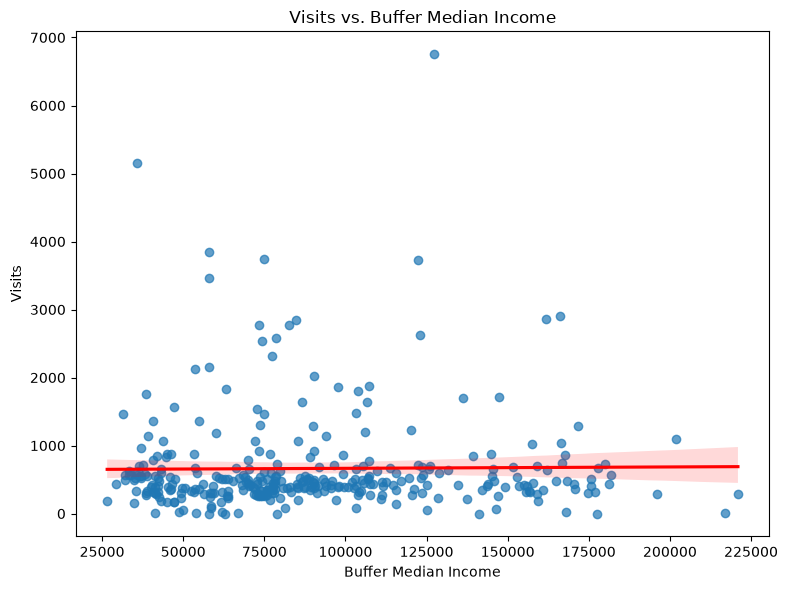

In [110]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plot_df = park_summary_25[['visits', 'buffer_median_income']].dropna()

plt.figure(figsize=(8, 6))
sns.regplot(
    data=plot_df,
    x='buffer_median_income',
    y='visits',
    scatter_kws={'alpha': 0.7},
    line_kws={'color': 'red'},
)
plt.title('Visits vs. Buffer Median Income')
plt.xlabel('Buffer Median Income')
plt.ylabel('Visits')
plt.tight_layout()
plt.show()

About 750 visits per park on average, regardless of surrounding median income level.

slope = 4.362e-06 hours per $1 (x 10,000 = 0.044 hours per $10k)
r²    = 0.020
p     = 0.0102


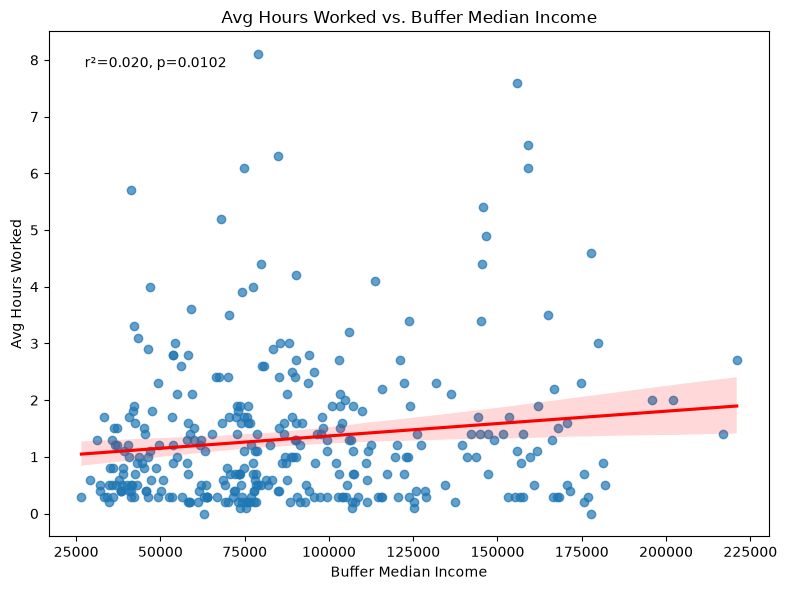

In [111]:
from scipy import stats

plot_df = park_summary_25[['avg_hours', 'buffer_median_income']].dropna()

res = stats.linregress(plot_df['buffer_median_income'], plot_df['avg_hours'])
print(f"slope = {res.slope:.4g} hours per $1 (x 10,000 = {res.slope*10000:.3f} hours per $10k)")
print(f"r²    = {res.rvalue**2:.3f}")
print(f"p     = {res.pvalue:.3g}")

plt.figure(figsize=(8, 6))
sns.regplot(
    data=plot_df,
    x='buffer_median_income',
    y='avg_hours',
    scatter_kws={'alpha': 0.7},
    line_kws={'color': 'red'},
)
plt.text(0.05, 0.95, f"r²={res.rvalue**2:.3f}, p={res.pvalue:.3g}",
         transform=plt.gca().transAxes, va='top')
plt.title('Avg Hours Worked vs. Buffer Median Income')
plt.xlabel('Buffer Median Income')
plt.ylabel('Avg Hours Worked')
plt.tight_layout()
plt.show()

Very weak statistical significance of hours worked to buffer median income.

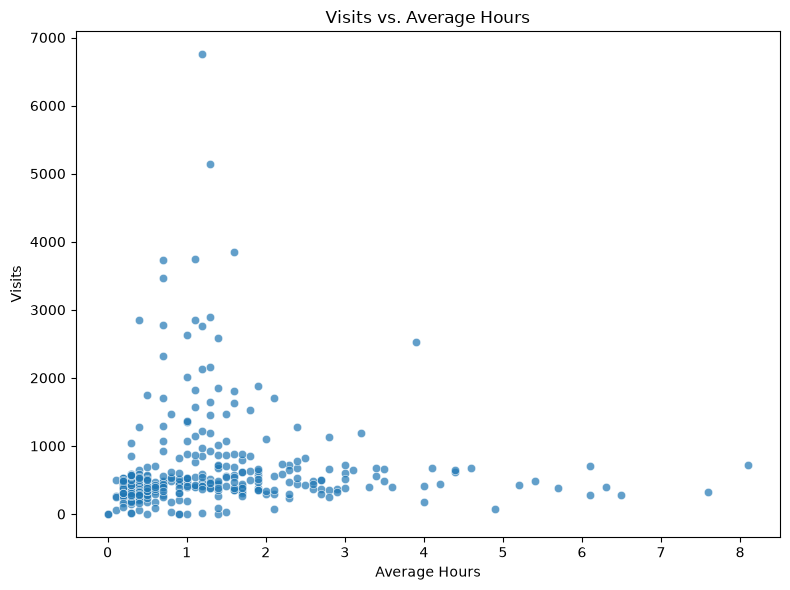

In [112]:
plot_df = park_summary_25[['visits', 'avg_hours']].dropna()

plt.figure(figsize=(8, 6))
sns.scatterplot(data=plot_df, x='avg_hours', y='visits', alpha=0.7)
plt.title('Visits vs. Average Hours')
plt.xlabel('Average Hours')
plt.ylabel('Visits')
plt.tight_layout()
plt.show()

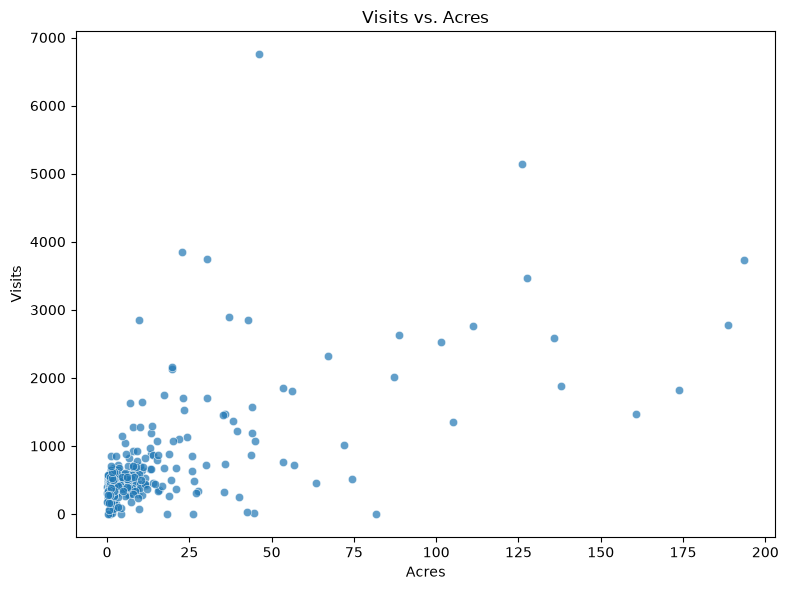

In [113]:
plot_df = park_summary_25[['visits', 'acres']].dropna()

plt.figure(figsize=(8, 6))
sns.scatterplot(data=plot_df, x='acres', y='visits', alpha=0.7)
plt.title('Visits vs. Acres')
plt.xlabel('Acres')
plt.ylabel('Visits')
plt.tight_layout()
plt.show()

#### Borough Summary

In [114]:
borough_summary = (
    park_summary_25
    .groupby('BOROUGH')
    .agg(
        num_parks=('gispropnum', 'count'),
        avg_crew_size=('avg_crew_size', 'mean'),
        avg_visits=('visits', 'mean'),
        avg_hours=('avg_hours', 'mean'),
    )
    .round(2)
    .reset_index()
)

borough_summary.head()

,BOROUGH,num_parks,avg_crew_size,avg_visits,avg_hours
0,B,93,2.20,714.25,1.67
1,M,69,3.32,755.20,1.62
2,Q,79,2.54,574.34,1.29
3,R,24,4.00,702.00,0.65
4,X,70,2.41,592.91,0.83


#### Results So Far

Income and Parks Department "hours worked", aka number of overall visits, seem to be weakly correlated, or not at all correlated to income level. Next, I'm going to loop in inspection data, which measures how good of a job the parks crews might be doing.

________________________________

#### Considering PIP Inspection Data

First, I'll bring back the PIP_Ratable column

In [115]:
ratable = properties.drop_duplicates('gispropnum')[['gispropnum', 'PIP_RATABLE']]

park_summary_25 = park_summary_25.merge(ratable, on='gispropnum', how='left', validate='one_to_one') # add PIP_RATABLE column to park_summary_25 df
park_summary_25['PIP_RATABLE'].value_counts(dropna=False)

PIP_RATABLE
True     257
False     77
NaN        1
Name: count, dtype: int64

In [116]:
ratable.head(3)

,gispropnum,PIP_RATABLE
0,X164A,False
1,X247,True
2,M125C,True


In [117]:
park_summary_25.head(5)

,gispropnum,NAME311,multipolygon,BOROUGH,TYPECATEGORY,SUBCATEGORY,visits,avg_crew_size,avg_hours,buffer_median_income,acres,PIP_RATABLE
0,B002,Amersfort Park,MULTIPOLYGON (((-73.93854175927676 40.62761792...,B,Neighborhood Park,Neighborhood Park,341,3.0,1.7,88989.447821,3.505070,True
1,B007,Bensonhurst Park,MULTIPOLYGON (((-74.00020282563159 40.59646464...,B,Recreational Field/Courts,Large Park,673,2.0,2.4,66387.747054,17.294833,True
2,B008,Betsy Head Park,MULTIPOLYGON (((-73.91189056137189 40.66222141...,B,Community Park,Large Park,651,2.0,3.1,43281.448458,10.556777,True
3,B012,Brower Park,MULTIPOLYGON (((-73.9429028809978 40.674715374...,B,Neighborhood Park,Large Park,1637,2.0,1.6,86616.349545,7.016308,True
4,B016,Maria Hernandez Park,MULTIPOLYGON (((-73.92251220650344 40.70351339...,B,Neighborhood Park,Large Park,828,2.0,2.5,88941.960900,6.724681,True


#### Bring in PIP Inspections

PIP Inspection data for Inpsection Year "2025" only.

In [118]:
pips = pd.read_csv('../data/Parks_Inspection_Program_–_Inspections_2025.csv')

pips.head(5)

,Prop ID,AMPSDistrict,Inspection ID,Season,Round,Date,BeginInspection,EndInspection,Inspection Year,inspector,inspector2,Overall Condition,Cleanliness,Safety Condition,Structural Condition,VisitorCount,Closed?,Comments,InspectionType,inspAddedDate
0,XZ475,06,195133,Winter,2,2025 Dec 16 12:00:00 AM,09:34:00,09:41:00,2025,63,NaN,A,A,NaN,NaN,NaN,NaN,"Features rated ""N"" are covered in snow",PIP,2025 Dec 16 01:01:00 PM
1,XZ19,06,195136,Winter,2,2025 Dec 16 12:00:00 AM,09:54:00,10:00:00,2025,63,NaN,A,A,NaN,NaN,NaN,NaN,"Features rated ""N"" are covered in snow",PIP,2025 Dec 16 01:13:00 PM
2,B353,18,195137,Winter,2,2025 Dec 16 12:00:00 AM,09:55:00,10:10:00,2025,31,NaN,A,A,NaN,NaN,0.0,NaN,Features with Ns were snow covered.,PIP,2025 Dec 16 01:15:00 PM
3,Q026,04,195144,Winter,2,2025 Dec 16 12:00:00 AM,08:40:00,08:55:00,2025,43,NaN,A,A,NaN,NaN,3.0,Partial Constr./Rest of Site Rated.,"Features rated ""N"" due to snow cover. Large c...",PIP,2025 Dec 16 01:46:00 PM
4,Q055,04,195145,Winter,2,2025 Dec 16 12:00:00 AM,08:55:00,09:00:00,2025,43,NaN,A,A,NaN,NaN,3.0,NaN,NaN,PIP,2025 Dec 16 01:51:00 PM


In [119]:
pips.shape

(6505, 20)

In [120]:
pip_properties = pd.read_csv('../data/Parks_Inspection_Program_-_All_Sites_(UNMAPPED)_20261015.csv')

pip_properties.head(5)

,PropNum,Prop ID,Boro,AMPSDistrict,Prop Name,Site Name,Prop Location,Site Location,Acres,Category,...,Council District,ZipCode,COMMUNITYBOARD,Jurisdiction,NYSAssembly,NYSSenate,USCongress,Precinct,PublicRestroom,SourceFC
0,B080B,B080B,B,13,WILLIAM J HENNESSY TRIANGLE,WILLIAM J HENNESSY TRIANGLE,S/S OCEAN PKWY & SEA BREEZE AVE & SURF AVE,S/S OCEAN PKWY & SEA BREEZE AVE & SURF AVE,0.0,Greenstreet,...,NaN,NaN,NaN,DPR,NaN,NaN,NaN,NaN,False,Unmapped
1,B169,B169-ZN01,B,13,Coney Island Beach & Boardwalk,CONEY ISLAND BEACH ZONE 1,"Corbin Pl. to W. 37 St., Boardwalk",CORBIN PL TO CONEY ISLAND AVE,0.0,Large Park,...,NaN,NaN,NaN,DPR,NaN,NaN,NaN,NaN,False,Unmapped
2,B169,B169-ZN02,B,13,Coney Island Beach & Boardwalk,CONEY ISLAND BEACH ZONE 2,"Corbin Pl. to W. 37 St., Boardwalk",CONEY ISLAND AVE TO B. 2ND ST,0.0,Large Park,...,NaN,NaN,NaN,DPR,NaN,NaN,NaN,NaN,False,Unmapped
3,B169,B169-ZN03,B,13,Coney Island Beach & Boardwalk,CONEY ISLAND BEACH ZONE 3,"Corbin Pl. to W. 37 St., Boardwalk",B. 2ND ST TO W 2ND ST,0.0,Large Park,...,NaN,NaN,NaN,DPR,NaN,NaN,NaN,NaN,False,Unmapped
4,B169,B169-ZN04,B,13,Coney Island Beach & Boardwalk,CONEY ISLAND BEACH ZONE 4,"Corbin Pl. to W. 37 St., Boardwalk",W 2ND ST TO W 10TH ST,0.0,Large Park,...,NaN,NaN,NaN,DPR,NaN,NaN,NaN,NaN,False,Unmapped


In [121]:
pips.columns

Index(['Prop ID', 'AMPSDistrict', 'Inspection ID', 'Season', 'Round', 'Date',
       'BeginInspection', 'EndInspection', 'Inspection Year', 'inspector',
       'inspector2', 'Overall Condition', 'Cleanliness', 'Safety Condition',
       'Structural Condition', 'VisitorCount', 'Closed?', 'Comments',
       'InspectionType', 'inspAddedDate'],
      dtype='str')

In [122]:
pip_properties.shape

(178, 23)

In [123]:
pips['Prop ID'].value_counts()

Prop ID
Q026         5
X118-ZN04    5
X010-ZN05    5
X196         5
M077-ZN04    5
            ..
QZ24         1
XZ277        1
BZ161        1
RZ240        1
XZ44         1
Name: count, Length: 3162, dtype: int64

In [124]:
pip_properties['Prop ID'].value_counts()

Prop ID
B080B        1
B169-ZN01    1
B169-ZN02    1
B169-ZN03    1
B169-ZN04    1
            ..
XZ295o       1
XZ314        1
XZ332        1
XZ65         1
XZ69o        1
Name: count, Length: 178, dtype: int64

In [125]:
pip_names = pips.merge(pip_properties[['Prop ID', 'Prop Name', 'Site Name']], left_on='Prop ID', right_on='Prop ID', how='left', validate='many_to_one')

pip_names.head(5)

,Prop ID,AMPSDistrict,Inspection ID,Season,Round,Date,BeginInspection,EndInspection,Inspection Year,inspector,...,Cleanliness,Safety Condition,Structural Condition,VisitorCount,Closed?,Comments,InspectionType,inspAddedDate,Prop Name,Site Name
0,XZ475,06,195133,Winter,2,2025 Dec 16 12:00:00 AM,09:34:00,09:41:00,2025,63,...,A,NaN,NaN,NaN,NaN,"Features rated ""N"" are covered in snow",PIP,2025 Dec 16 01:01:00 PM,NaN,NaN
1,XZ19,06,195136,Winter,2,2025 Dec 16 12:00:00 AM,09:54:00,10:00:00,2025,63,...,A,NaN,NaN,NaN,NaN,"Features rated ""N"" are covered in snow",PIP,2025 Dec 16 01:13:00 PM,NaN,NaN
2,B353,18,195137,Winter,2,2025 Dec 16 12:00:00 AM,09:55:00,10:10:00,2025,31,...,A,NaN,NaN,0.0,NaN,Features with Ns were snow covered.,PIP,2025 Dec 16 01:15:00 PM,NaN,NaN
3,Q026,04,195144,Winter,2,2025 Dec 16 12:00:00 AM,08:40:00,08:55:00,2025,43,...,A,NaN,NaN,3.0,Partial Constr./Rest of Site Rated.,"Features rated ""N"" due to snow cover. Large c...",PIP,2025 Dec 16 01:46:00 PM,NaN,NaN
4,Q055,04,195145,Winter,2,2025 Dec 16 12:00:00 AM,08:55:00,09:00:00,2025,43,...,A,NaN,NaN,3.0,NaN,NaN,PIP,2025 Dec 16 01:51:00 PM,NaN,NaN


In [126]:
pip_names.shape

(6505, 22)

In [127]:
pip_names.columns

Index(['Prop ID', 'AMPSDistrict', 'Inspection ID', 'Season', 'Round', 'Date',
       'BeginInspection', 'EndInspection', 'Inspection Year', 'inspector',
       'inspector2', 'Overall Condition', 'Cleanliness', 'Safety Condition',
       'Structural Condition', 'VisitorCount', 'Closed?', 'Comments',
       'InspectionType', 'inspAddedDate', 'Prop Name', 'Site Name'],
      dtype='str')

In [128]:
pip_names = pip_names[['Prop ID', 'BeginInspection', 'EndInspection', 'Overall Condition', 'Cleanliness', 'Prop Name', 'Site Name']]

pip_names.head(5)

,Prop ID,BeginInspection,EndInspection,Overall Condition,Cleanliness,Prop Name,Site Name
0,XZ475,09:34:00,09:41:00,A,A,NaN,NaN
1,XZ19,09:54:00,10:00:00,A,A,NaN,NaN
2,B353,09:55:00,10:10:00,A,A,NaN,NaN
3,Q026,08:40:00,08:55:00,A,A,NaN,NaN
4,Q055,08:55:00,09:00:00,A,A,NaN,NaN


#### Reduce PIP data to One Per Park

First, find time length per inspection

In [129]:
pip_names['inspection_length'] = (
    pd.to_timedelta(pip_names['EndInspection']) - pd.to_timedelta(pip_names['BeginInspection'])
).dt.total_seconds() / 3600

pip_names['inspection_length'].describe()

count    6505.000000
mean        0.414304
std         0.323131
min        -0.416667
25%         0.166667
50%         0.333333
75%         0.583333
max         4.100000
Name: inspection_length, dtype: float64

Some inspections are negative hours, which means a few rows have data entry errors. I'm going to turn those blank, so they dont get deleted, but aren't included in total time spent average per park.

In [130]:
pip_names.loc[pip_names['inspection_length'] <= 0, 'inspection_length'] = None # turns all negative or zero values into NaN values, because they are not valid inspection lengths
pip_names['inspection_length'].describe()

count    6500.000000
mean        0.414726
std         0.322863
min         0.033333
25%         0.166667
50%         0.333333
75%         0.583333
max         4.100000
Name: inspection_length, dtype: float64

In [131]:
pip_per_park_25 = (
    pip_names.groupby('Prop ID')['inspection_length']
    .mean()
    .reset_index()
    .rename(columns={'inspection_length': 'avg_inspection_hours'})
)

pip_per_park_25.head()

,Prop ID,avg_inspection_hours
0,B001,0.438889
1,B002,0.375000
2,B003,0.166667
3,B006,0.166667
4,B007,0.722222


In [132]:
len(pip_per_park_25['Prop ID'].unique())

3162

Then, find avg cleanliness, avg overall condition and number of inpsection visits

In [133]:
rating_map = {'A': 1, 'U': 0}  # 'N' (and anything else) becomes NaN and is ignored in the mean

pip_summary = (
    pip_names
    .assign(
        overall_num=pip_names['Overall Condition'].str.strip().str.upper().map(rating_map),
        clean_num=pip_names['Cleanliness'].str.strip().str.upper().map(rating_map),
    )
    .groupby('Prop ID')
    .agg(
        avg_overall_condition=('overall_num', 'mean'),
        avg_cleanliness=('clean_num', 'mean'),
        num_inspections=('Prop ID', 'size'),
    )
    .reset_index()
)

pip_summary.head()

,Prop ID,avg_overall_condition,avg_cleanliness,num_inspections
0,B001,0.0,0.666667,3
1,B002,1.0,1.000000,2
2,B003,1.0,1.000000,2
3,B006,1.0,1.000000,1
4,B007,0.5,1.000000,3


In [134]:
pip_summary.shape

(3162, 4)

In [135]:
pip_per_park_25 = pip_summary.merge(pip_per_park_25, on='Prop ID', how='left', validate='one_to_one')

pip_per_park_25.head()

,Prop ID,avg_overall_condition,avg_cleanliness,num_inspections,avg_inspection_hours
0,B001,0.0,0.666667,3,0.438889
1,B002,1.0,1.000000,2,0.375000
2,B003,1.0,1.000000,2,0.166667
3,B006,1.0,1.000000,1,0.166667
4,B007,0.5,1.000000,3,0.722222


#### Merge PIP Data

In [136]:
park_summary_25.head()

,gispropnum,NAME311,multipolygon,BOROUGH,TYPECATEGORY,SUBCATEGORY,visits,avg_crew_size,avg_hours,buffer_median_income,acres,PIP_RATABLE
0,B002,Amersfort Park,MULTIPOLYGON (((-73.93854175927676 40.62761792...,B,Neighborhood Park,Neighborhood Park,341,3.0,1.7,88989.447821,3.505070,True
1,B007,Bensonhurst Park,MULTIPOLYGON (((-74.00020282563159 40.59646464...,B,Recreational Field/Courts,Large Park,673,2.0,2.4,66387.747054,17.294833,True
2,B008,Betsy Head Park,MULTIPOLYGON (((-73.91189056137189 40.66222141...,B,Community Park,Large Park,651,2.0,3.1,43281.448458,10.556777,True
3,B012,Brower Park,MULTIPOLYGON (((-73.9429028809978 40.674715374...,B,Neighborhood Park,Large Park,1637,2.0,1.6,86616.349545,7.016308,True
4,B016,Maria Hernandez Park,MULTIPOLYGON (((-73.92251220650344 40.70351339...,B,Neighborhood Park,Large Park,828,2.0,2.5,88941.960900,6.724681,True


In [137]:
park_summary_inspections = park_summary_25.merge(pip_per_park_25, left_on='gispropnum', right_on='Prop ID', how='left', validate='one_to_one')

park_summary_inspections.head(3)

,gispropnum,NAME311,multipolygon,BOROUGH,TYPECATEGORY,SUBCATEGORY,visits,avg_crew_size,avg_hours,buffer_median_income,acres,PIP_RATABLE,Prop ID,avg_overall_condition,avg_cleanliness,num_inspections,avg_inspection_hours
0,B002,Amersfort Park,MULTIPOLYGON (((-73.93854175927676 40.62761792...,B,Neighborhood Park,Neighborhood Park,341,3.0,1.7,88989.447821,3.505070,True,B002,1.0,1.0,2.0,0.375000
1,B007,Bensonhurst Park,MULTIPOLYGON (((-74.00020282563159 40.59646464...,B,Recreational Field/Courts,Large Park,673,2.0,2.4,66387.747054,17.294833,True,B007,0.5,1.0,3.0,0.722222
2,B008,Betsy Head Park,MULTIPOLYGON (((-73.91189056137189 40.66222141...,B,Community Park,Large Park,651,2.0,3.1,43281.448458,10.556777,True,B008,0.5,1.0,2.0,0.691667


In [138]:
park_summary_inspections.shape

(335, 17)

#### Plot Pip Data

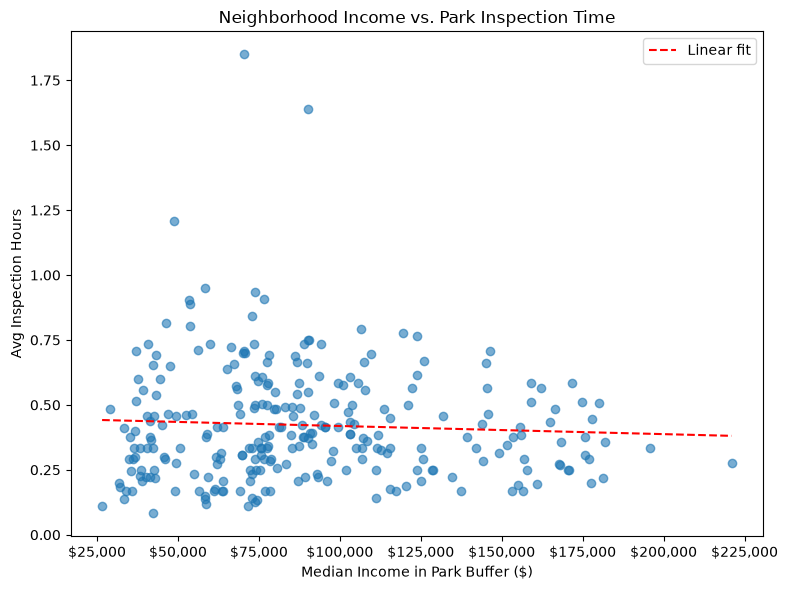

In [139]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = park_summary_inspections[['buffer_median_income', 'avg_inspection_hours']].dropna()

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(plot_df['buffer_median_income'], plot_df['avg_inspection_hours'], alpha=0.6)

# optional trend line
m, b = np.polyfit(plot_df['buffer_median_income'], plot_df['avg_inspection_hours'], 1)
x = np.linspace(plot_df['buffer_median_income'].min(), plot_df['buffer_median_income'].max(), 100)
ax.plot(x, m * x + b, color='red', linestyle='--', label='Linear fit')

ax.set_xlabel('Median Income in Park Buffer ($)')
ax.set_ylabel('Avg Inspection Hours')
ax.set_title('Neighborhood Income vs. Park Inspection Time')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'${v:,.0f}'))
ax.legend()

plt.tight_layout()
plt.show()

#### Add Pips to Borough Summary

In [140]:
borough_summary.head()

,BOROUGH,num_parks,avg_crew_size,avg_visits,avg_hours
0,B,93,2.20,714.25,1.67
1,M,69,3.32,755.20,1.62
2,Q,79,2.54,574.34,1.29
3,R,24,4.00,702.00,0.65
4,X,70,2.41,592.91,0.83


In [141]:
park_summary_inspections.head()

,gispropnum,NAME311,multipolygon,BOROUGH,TYPECATEGORY,SUBCATEGORY,visits,avg_crew_size,avg_hours,buffer_median_income,acres,PIP_RATABLE,Prop ID,avg_overall_condition,avg_cleanliness,num_inspections,avg_inspection_hours
0,B002,Amersfort Park,MULTIPOLYGON (((-73.93854175927676 40.62761792...,B,Neighborhood Park,Neighborhood Park,341,3.0,1.7,88989.447821,3.505070,True,B002,1.0,1.0,2.0,0.375000
1,B007,Bensonhurst Park,MULTIPOLYGON (((-74.00020282563159 40.59646464...,B,Recreational Field/Courts,Large Park,673,2.0,2.4,66387.747054,17.294833,True,B007,0.5,1.0,3.0,0.722222
2,B008,Betsy Head Park,MULTIPOLYGON (((-73.91189056137189 40.66222141...,B,Community Park,Large Park,651,2.0,3.1,43281.448458,10.556777,True,B008,0.5,1.0,2.0,0.691667
3,B012,Brower Park,MULTIPOLYGON (((-73.9429028809978 40.674715374...,B,Neighborhood Park,Large Park,1637,2.0,1.6,86616.349545,7.016308,True,B012,1.0,1.0,2.0,0.541667
4,B016,Maria Hernandez Park,MULTIPOLYGON (((-73.92251220650344 40.70351339...,B,Neighborhood Park,Large Park,828,2.0,2.5,88941.960900,6.724681,True,B016,0.0,0.8,5.0,0.733333


In [142]:
len(park_summary_inspections)

335

In [143]:
pd.DataFrame(park_summary_inspections).to_csv('../output/park_summary_inspections_2025.csv', index=False)

Now I have a list of all measured parks with cleanup crew data and inspection data for each row. I can look closer at this data in Google Sheets.

In [144]:
borough_summary_2 = (
    park_summary_inspections
    .groupby('BOROUGH')
    .agg(
        num_parks=('gispropnum', 'count'),
        avg_condition=('avg_overall_condition', 'mean'),
        avg_cleanliness=('avg_cleanliness', 'mean'),
        avg_num_inspections=('num_inspections', 'mean'),
        avg_inspection_hours=('avg_inspection_hours', 'mean'),
    )
    .round(2)
    .reset_index()
)

borough_summary_2.head()

,BOROUGH,num_parks,avg_condition,avg_cleanliness,avg_num_inspections,avg_inspection_hours
0,B,93,0.78,0.87,2.53,0.47
1,M,69,0.79,0.84,2.59,0.42
2,Q,79,0.82,0.87,2.53,0.44
3,R,24,0.97,1.00,2.79,0.33
4,X,70,0.87,0.91,2.68,0.37


In [145]:
borough_summary_new = pd.merge(borough_summary, borough_summary_2, how='left', on='BOROUGH')
borough_summary_new = borough_summary_new.drop(columns=['num_parks_y']).rename(columns={'num_parks_x': 'num_parks'})

borough_summary_new.head()

,BOROUGH,num_parks,avg_crew_size,avg_visits,avg_hours,avg_condition,avg_cleanliness,avg_num_inspections,avg_inspection_hours
0,B,93,2.20,714.25,1.67,0.78,0.87,2.53,0.47
1,M,69,3.32,755.20,1.62,0.79,0.84,2.59,0.42
2,Q,79,2.54,574.34,1.29,0.82,0.87,2.53,0.44
3,R,24,4.00,702.00,0.65,0.97,1.00,2.79,0.33
4,X,70,2.41,592.91,0.83,0.87,0.91,2.68,0.37


In [146]:
borough_summary['avg_hours'].mean()

np.float64(1.2120000000000002)

Briefly what this tells us: 

In parks under 20 acres large (this excludes most Flagship Parks and large parks like Freshkills), Brooklyn saw the lowest overall condition rating despite reporting more average cleaning hours spent per park than every other borough. It also reported the most visits, but also has the most parks in the list. Interestingly, the cleaning crew size was the lowest, reporting an average of only 2.1 cleaning workers per park on average. 

This also tells us that the number of parks in a borough may determine how many cleaning crew members can be dispatched per park. Brooklyn has 76 parks : 2.11 crew members. Bronx has 66 parks : 2.44 crew members. Meanwhile, Staten Island only has 20 parks : 4.1 crew members. (Again, this dataset does not include parks over 20 acres.)

#### I had Claude help with the following:

This is a statistical model measuring avg_cleanliness relative to each borough's parks, then measuring the trend. This compares park buffer median incomes only to other parks in the same borough, not all parks in the dataset.

In [147]:
import statsmodels.formula.api as smf

model = smf.ols(
    'avg_cleanliness ~ buffer_median_income + np.log(acres) + C(TYPECATEGORY) + C(BOROUGH) + num_inspections',
    data=park_summary_inspections.dropna()
).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        avg_cleanliness   R-squared:                       0.122
Model:                            OLS   Adj. R-squared:                  0.090
Method:                 Least Squares   F-statistic:                     3.837
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           0.000146
Time:                        21:08:38   Log-Likelihood:                 24.604
No. Observations:                 258   AIC:                            -29.21
Df Residuals:                     248   BIC:                             6.321
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                                   coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------

This looks at income influence by borough, rather than overall. According to this analysis for buffer_median_income, this data shows: Per $10k of income, that’s about +0.019 cleanliness (about 2 percentage points), holding borough, park type, size, and inspection count constant. A park in a neighborhood $50k richer scores about 10 points higher.

The math works like this: Under coeficient ("coef"), the result for buffer_median_income = 0.00000191, which means +0.00000191% avg_cleanliness per +$1. 
Multiply that by 10,000, and we get +0.0191 per +$10,000. Turned into a percentage, that's about +2% average cleanliness for every $10,000 buffer_income increase, relative to each borough.
So on average, if Neighborhood A has an average income of $50,000 per year, and Neighborhood B has an average income of $100,000 per year, Neighborhood B's parks will be cleaner on average by about 10 percentage points.

For analysis 02, I'll be measuring demographic data rather than income: nearby population density, race and ethnicity composition, renter share, and composite index (e.g., NYC’s Neighborhood Equity or Social Vulnerability measures).

The analysis above ultimately shows me that while income has a small statistical influence on park conditions, there are other factors that are more significant.